### *IMPORTING ALL THE REQUIRED LIBRARIES*

In [1]:
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder,StandardScaler,OneHotEncoder
from sklearn.feature_selection import chi2
from sklearn.model_selection import train_test_split,cross_val_score
from sklearn.tree import DecisionTreeClassifier,plot_tree
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score,log_loss,precision_score,recall_score,f1_score,confusion_matrix,ConfusionMatrixDisplay,classification_report,roc_curve, roc_auc_score
from sklearn.model_selection import GridSearchCV

#### *LOAD THE DATASET*

In [2]:
df=pd.read_csv('breast_cancer.csv')

#### *UNDERSTANDING THE DATA*

In [3]:
df.shape

(569, 33)

In [4]:
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [5]:
df.tail()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,NaN
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,NaN
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,NaN
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,NaN
568,92751,B,7.76,24.54,47.92,181.0,0.05263,0.04362,0.00000,0.00000,...,30.37,59.16,268.6,0.08996,0.06444,0.0000,0.0000,0.2871,0.07039,NaN


In [6]:
df.describe()

,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,0.0
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,NaN
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,NaN
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,NaN
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,NaN
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,NaN
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,NaN
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,NaN


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [8]:
df.isnull().sum()

id                           0
diagnosis                    0
radius_mean                  0
texture_mean                 0
perimeter_mean               0
area_mean                    0
smoothness_mean              0
compactness_mean             0
concavity_mean               0
concave points_mean          0
symmetry_mean                0
fractal_dimension_mean       0
radius_se                    0
texture_se                   0
perimeter_se                 0
area_se                      0
smoothness_se                0
compactness_se               0
concavity_se                 0
concave points_se            0
symmetry_se                  0
fractal_dimension_se         0
radius_worst                 0
texture_worst                0
perimeter_worst              0
area_worst                   0
smoothness_worst             0
compactness_worst            0
concavity_worst              0
concave points_worst         0
symmetry_worst               0
fractal_dimension_worst      0
Unnamed:

#### *There are null values present will remove them in data cleaning.*

In [9]:
df.duplicated().sum()

np.int64(0)

#### *There are no duplicates in the dataset.*

### *EXPLORATORY DATA ANALYSIS*

##### *HISTOGRAM*

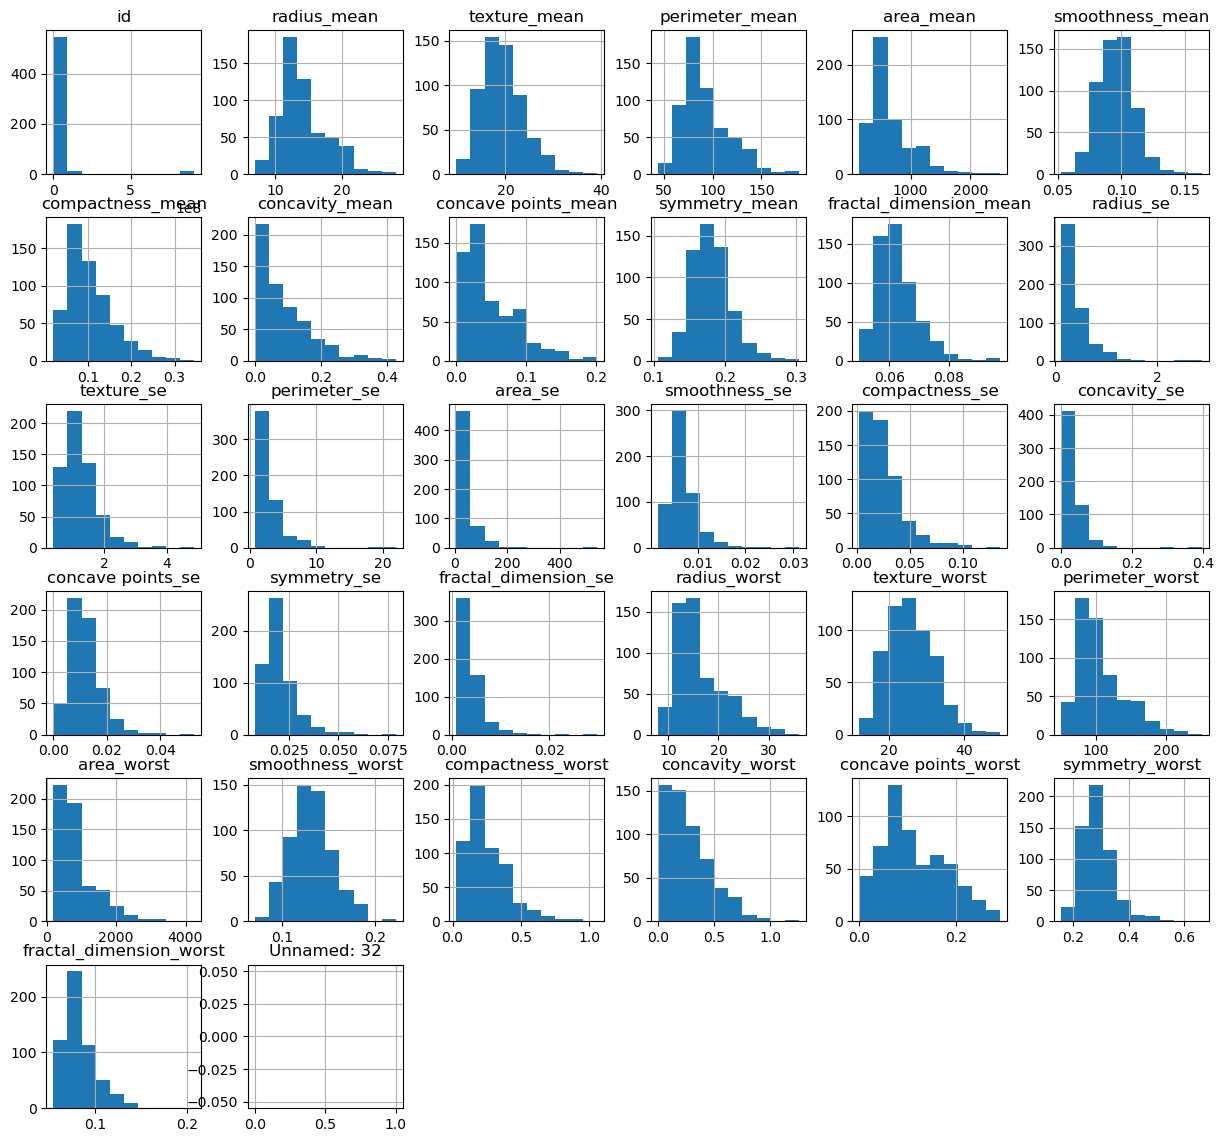

In [10]:
df.hist(figsize=(15,14))
plt.show()

*There are possibilities of many outliers in many features, and many are right skeweness.*

##### *SCATTER PLOT*

*Radius Mean vs Perimeter Mean*

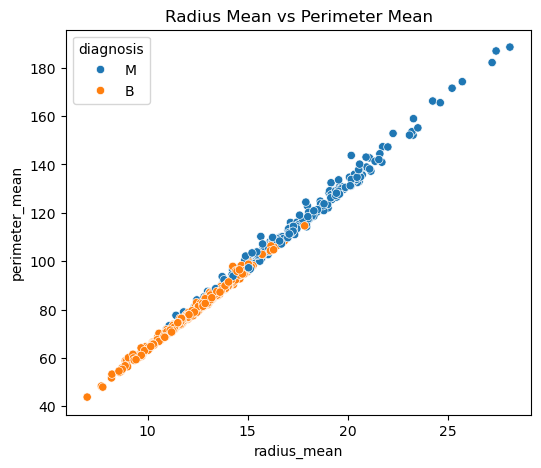

In [11]:
plt.figure(figsize=(6,5))
sns.scatterplot(data=df,
                x='radius_mean',
                y='perimeter_mean',
                hue='diagnosis')
plt.title("Radius Mean vs Perimeter Mean")
plt.show()

* As radius increases, perimeter increases almost linearly.
* Malignant tumors generally appear toward the higher values.

*Radius Mean vs Area Mean*

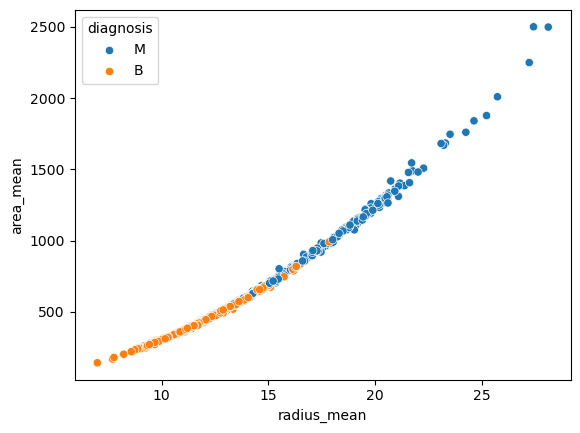

In [12]:
sns.scatterplot(data=df,
                x='radius_mean',
                y='area_mean',
                hue='diagnosis')
plt.show()

* Larger radius usually means larger area.
* You can see the clustering of benign and malignant samples.

*Perimeter Mean vs Area Mean*

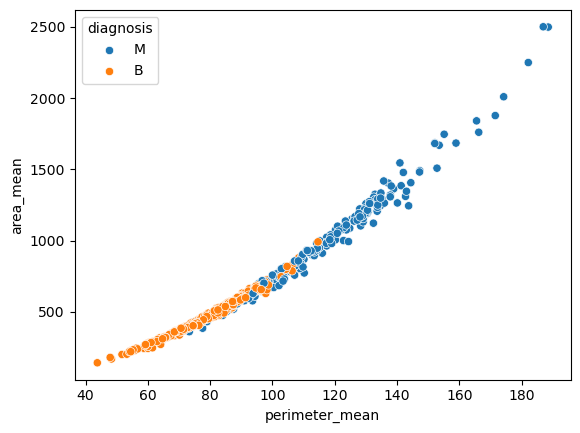

In [13]:
sns.scatterplot(data=df,
                x='perimeter_mean',
                y='area_mean',
                hue='diagnosis')
plt.show()

*Concavity Mean vs Concave Points Mean*

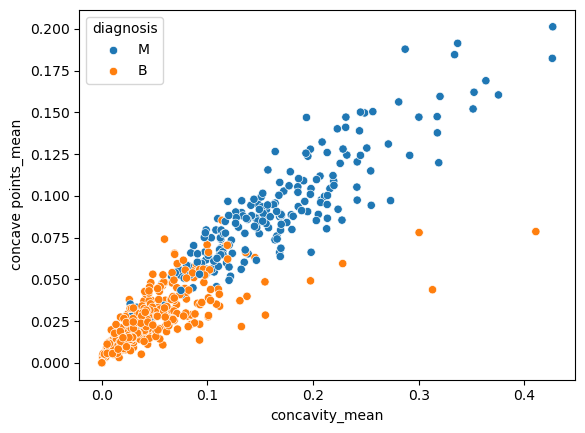

In [14]:
sns.scatterplot(data=df,
                x='concavity_mean',
                y='concave points_mean',
                hue='diagnosis')
plt.show()

* More inward dents (concavity) usually lead to more concave points.
* Malignant tumors tend to have higher values.

*Compactness Mean vs Concavity Mean*

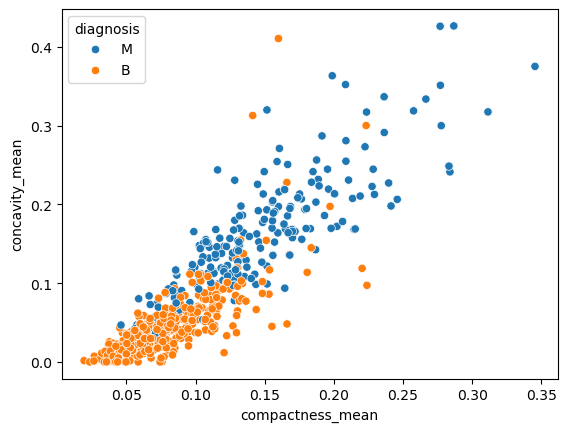

In [15]:
sns.scatterplot(data=df,
                x='compactness_mean',
                y='concavity_mean',
                hue='diagnosis')
plt.show()

*Radius Worst vs Area Worst*

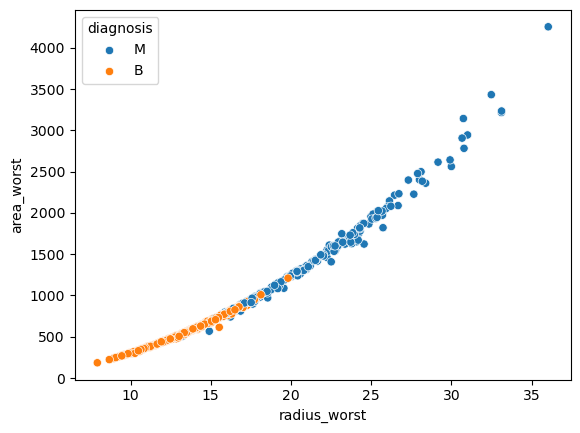

In [16]:
sns.scatterplot(data=df,
                x='radius_worst',
                y='area_worst',
                hue='diagnosis')
plt.show()

*Perimeter Worst vs Area Worst*

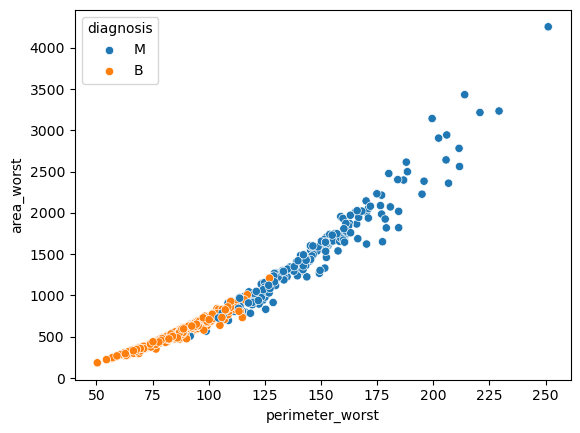

In [17]:
sns.scatterplot(data=df,
                x='perimeter_worst',
                y='area_worst',
                hue='diagnosis')
plt.show()

*Diagnosis*

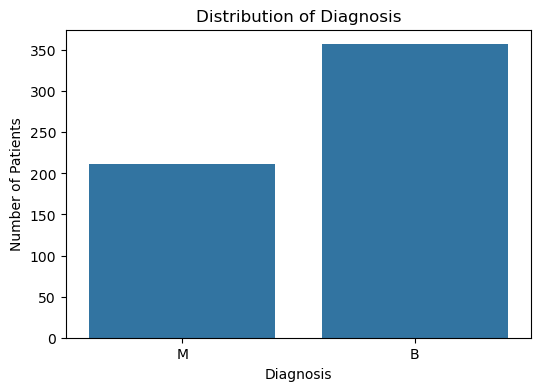

In [18]:
plt.figure(figsize=(6,4))
sns.countplot(x='diagnosis', data=df)
plt.title("Distribution of Diagnosis")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Patients")
plt.show()

*BOX PLOTS*

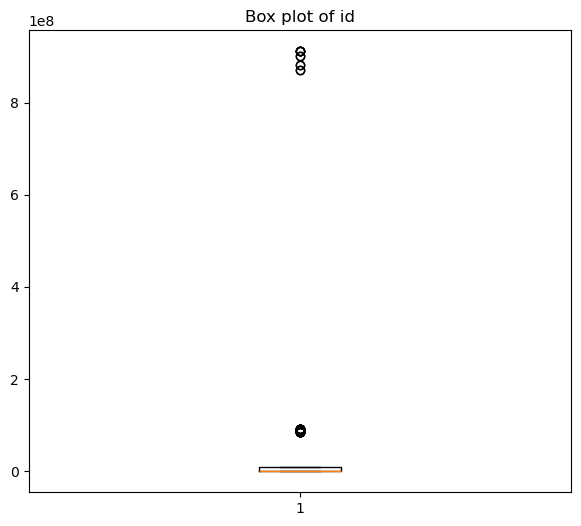

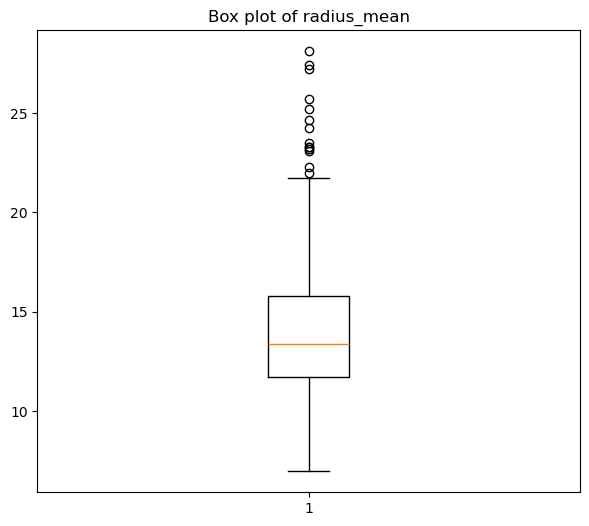

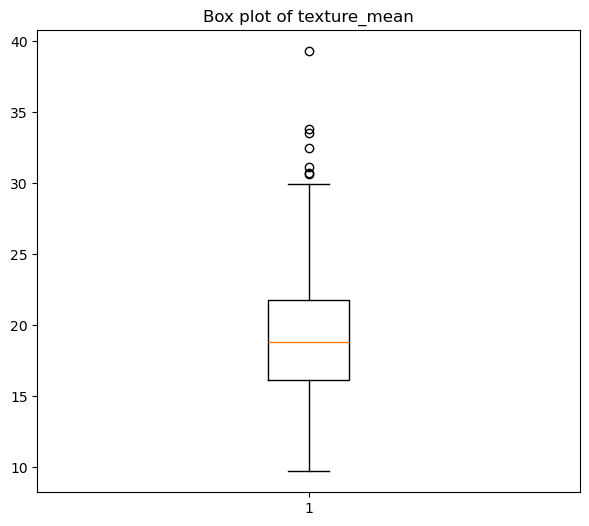

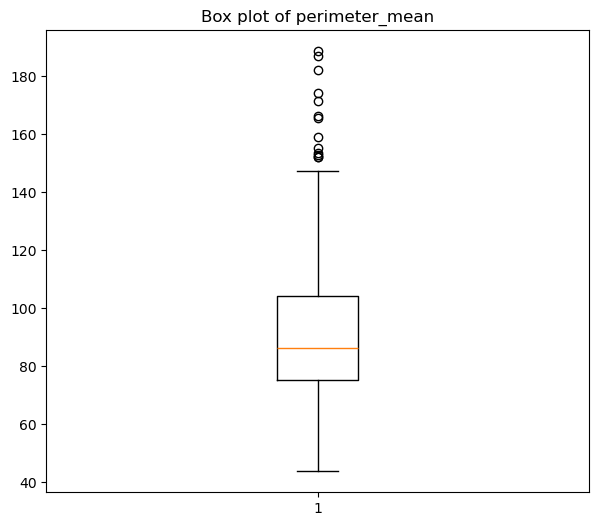

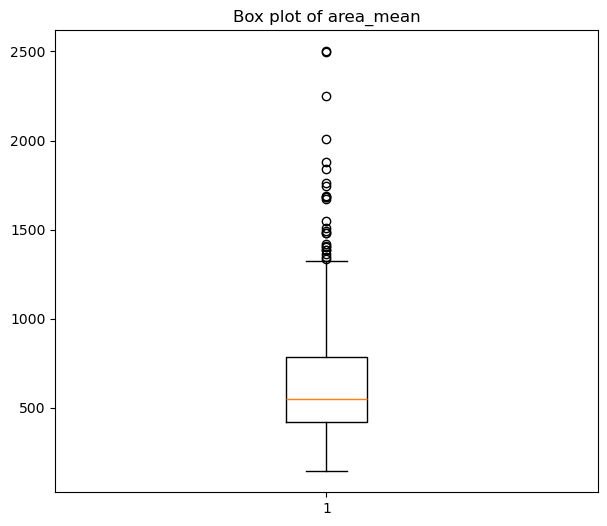

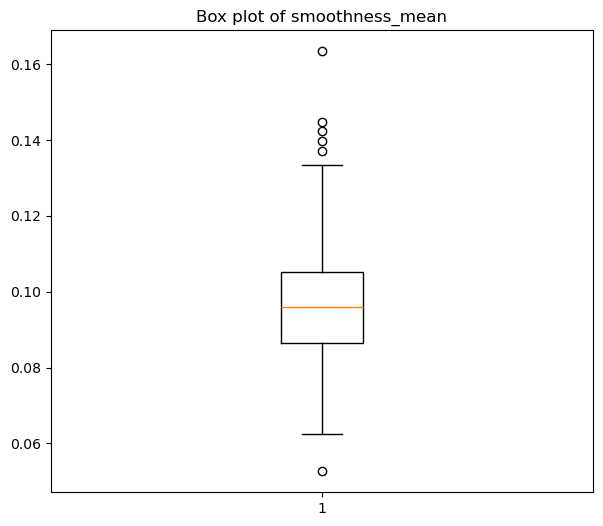

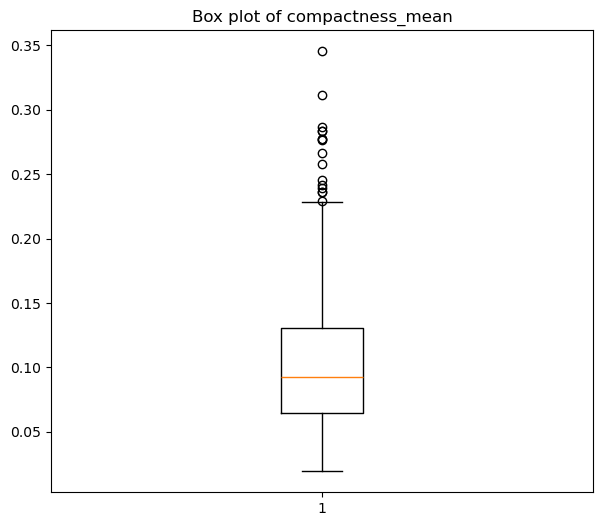

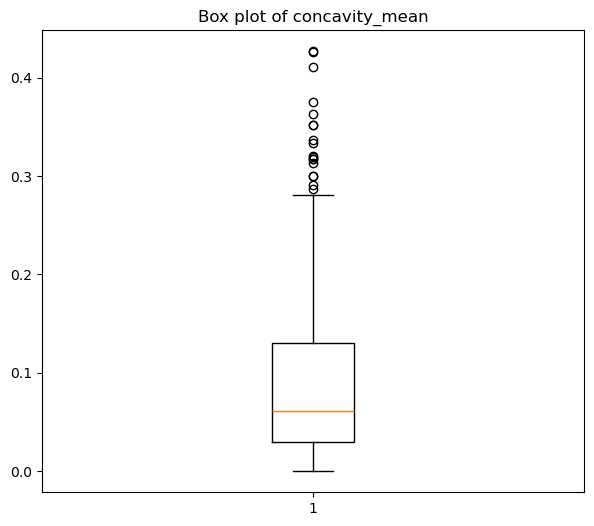

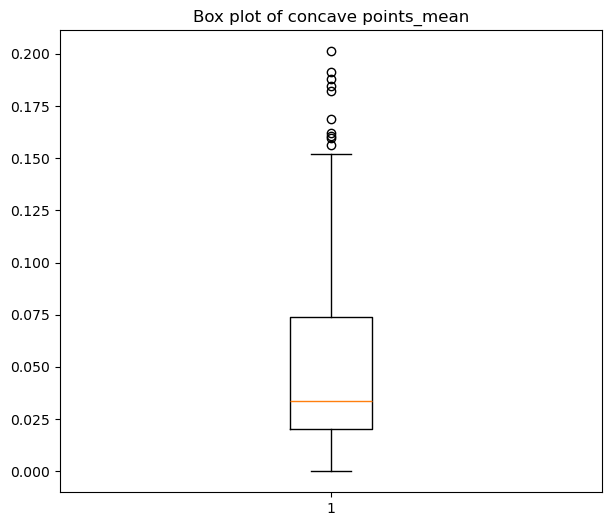

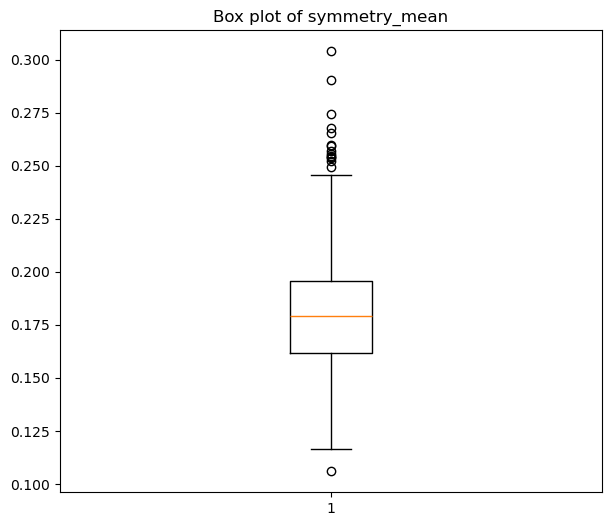

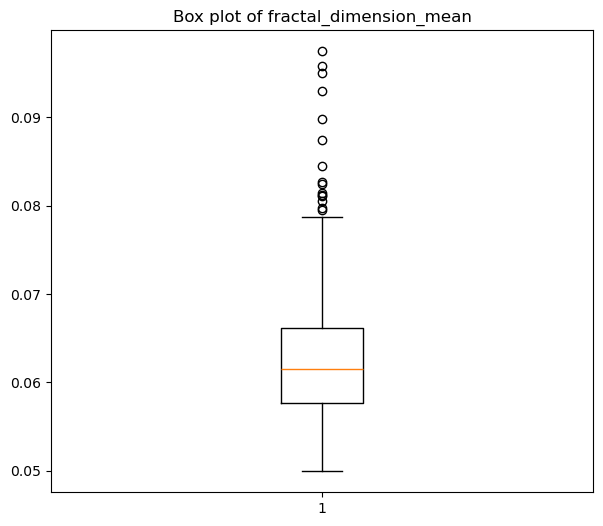

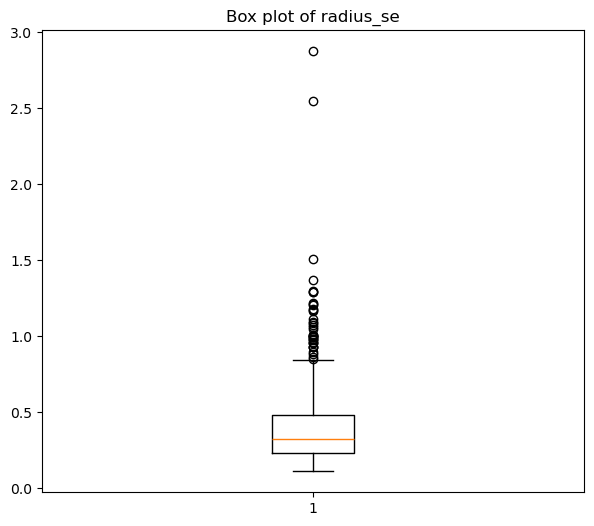

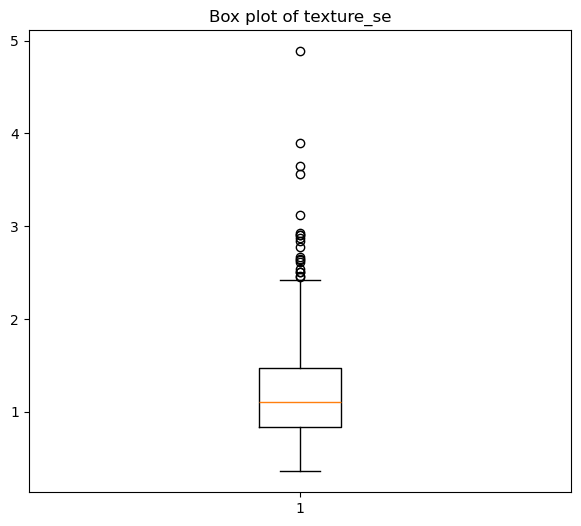

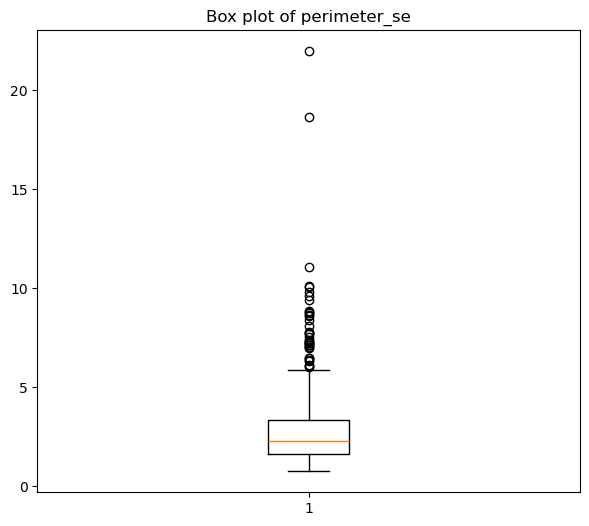

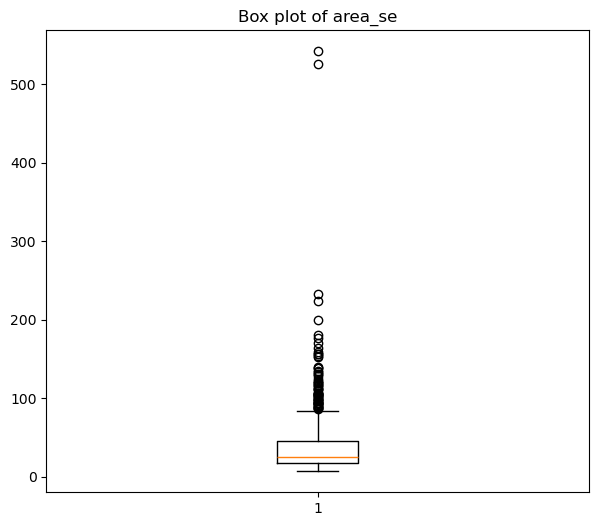

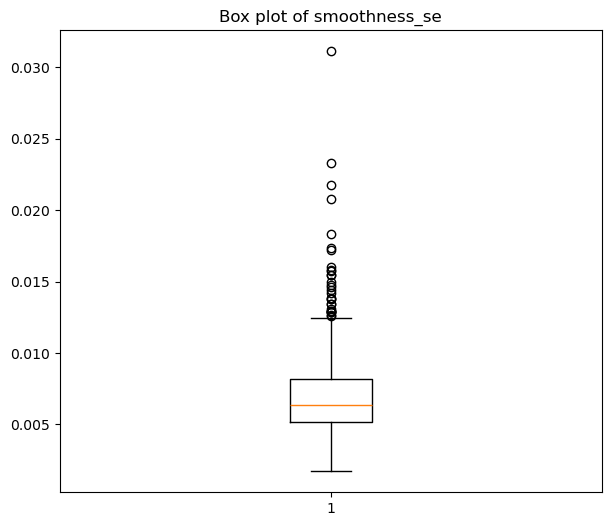

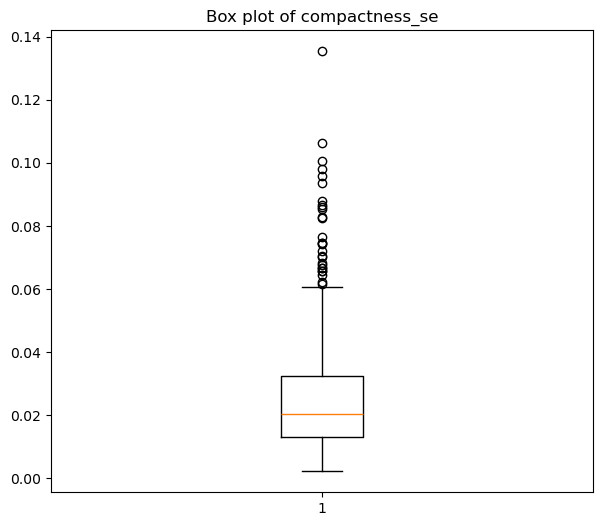

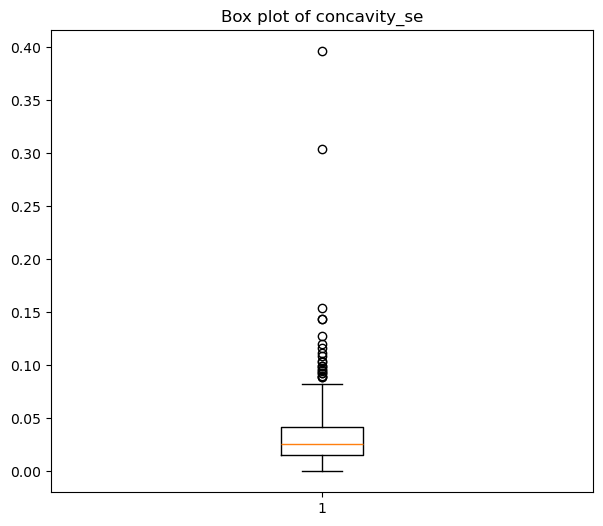

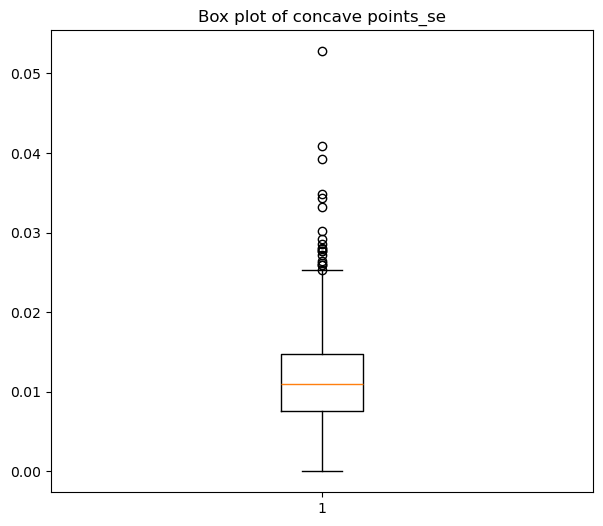

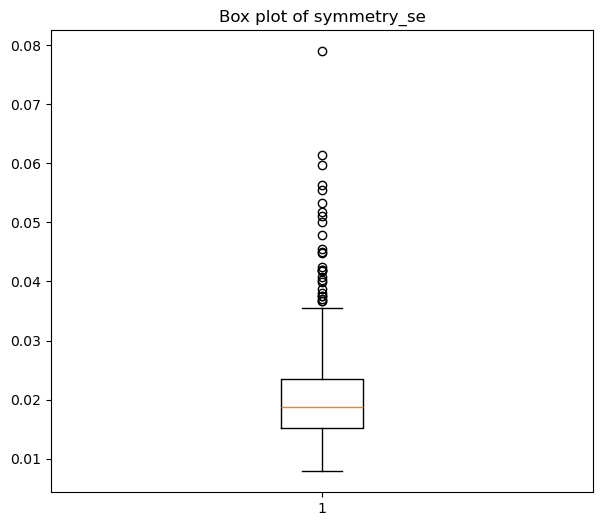

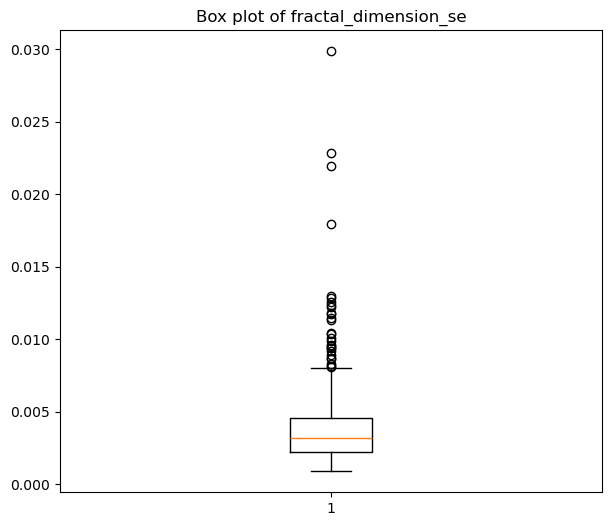

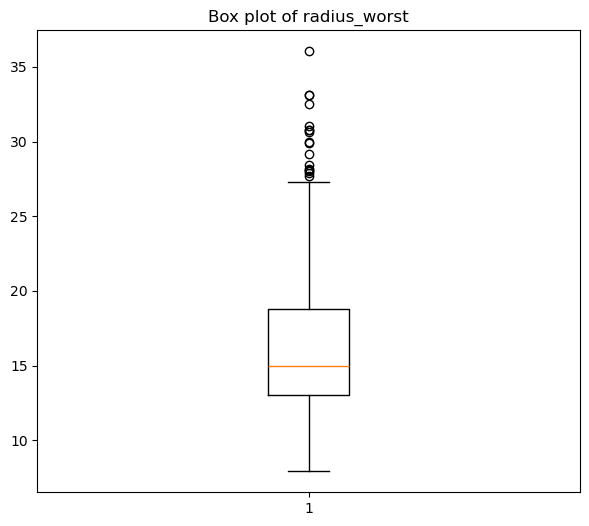

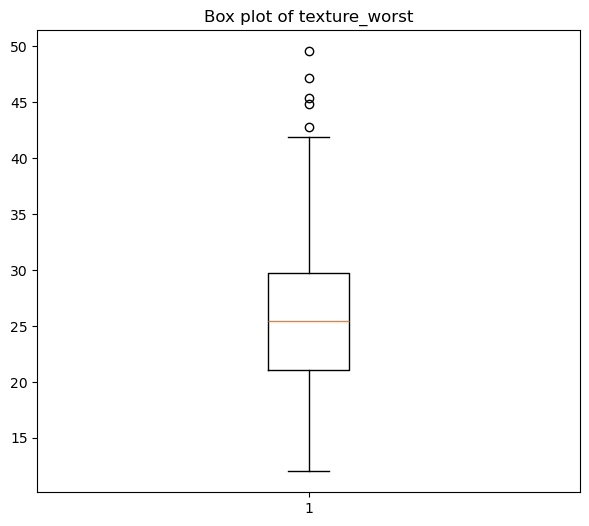

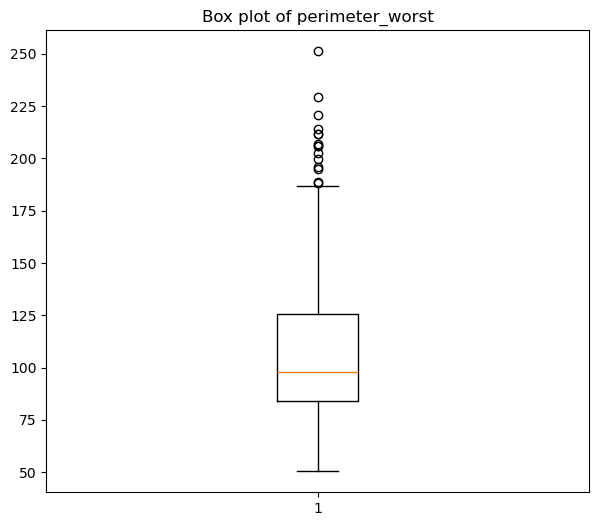

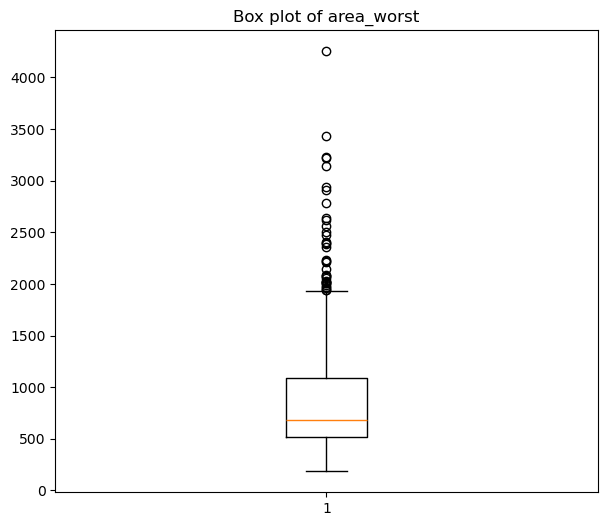

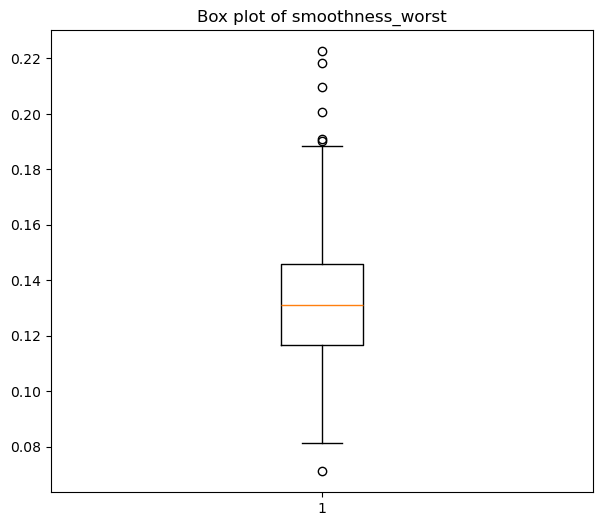

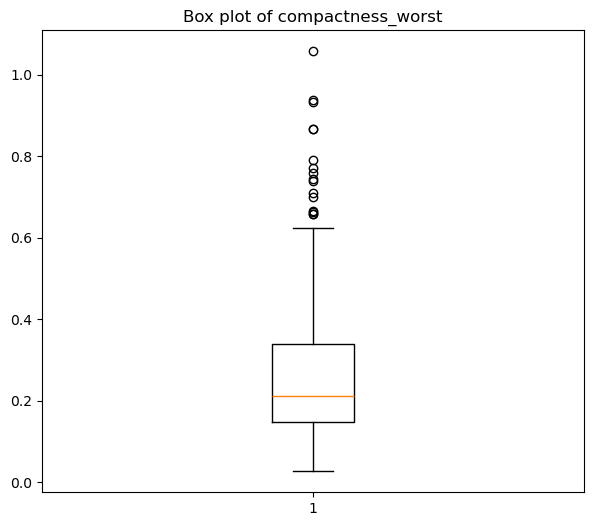

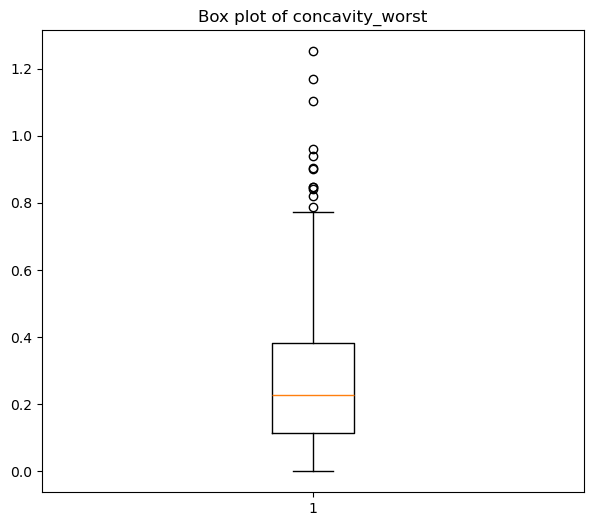

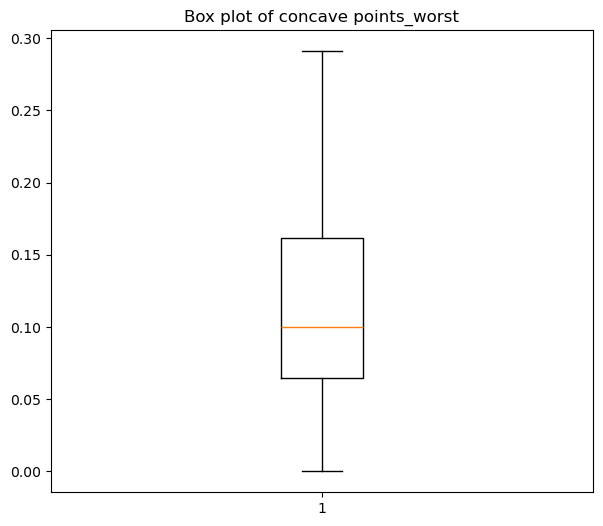

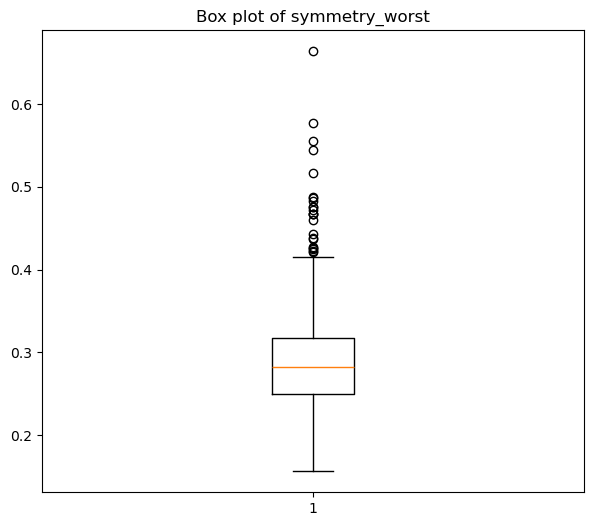

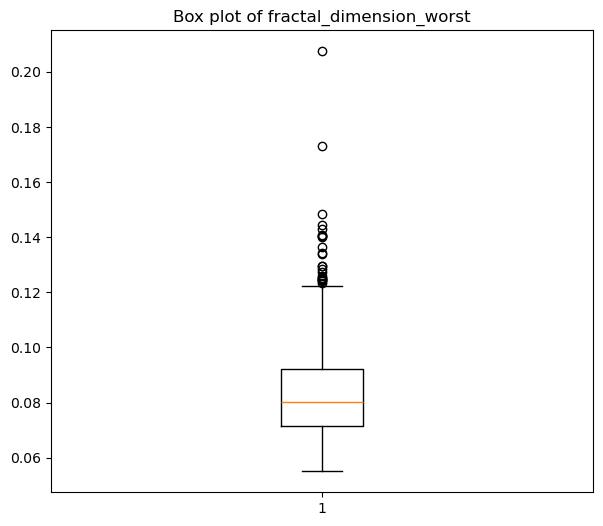

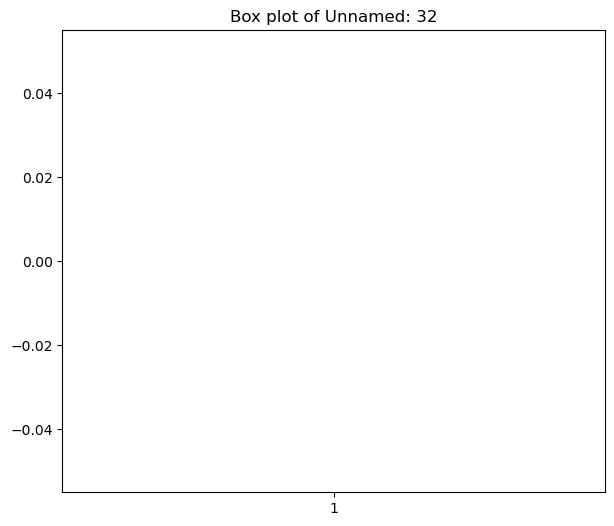

In [19]:
num_cols=df.select_dtypes(include='number').columns
for i in num_cols:
    plt.figure(figsize=(7,6))
    plt.boxplot(df[i])
    plt.title(f"Box plot of {i}")
    plt.show()

#### *DATA CLEANING*

*Remove unwanted columns*

In [20]:
df=df.drop(['id','Unnamed: 32'],axis=1)

In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   diagnosis                569 non-null    object 
 1   radius_mean              569 non-null    float64
 2   texture_mean             569 non-null    float64
 3   perimeter_mean           569 non-null    float64
 4   area_mean                569 non-null    float64
 5   smoothness_mean          569 non-null    float64
 6   compactness_mean         569 non-null    float64
 7   concavity_mean           569 non-null    float64
 8   concave points_mean      569 non-null    float64
 9   symmetry_mean            569 non-null    float64
 10  fractal_dimension_mean   569 non-null    float64
 11  radius_se                569 non-null    float64
 12  texture_se               569 non-null    float64
 13  perimeter_se             569 non-null    float64
 14  area_se                  5

*Outlier Treatment*

In [22]:
df.shape

(569, 31)

In [23]:
num_cols=df.select_dtypes(include='number').columns
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR
    df[col]=df[col].clip(lower_limit,upper_limit)

*EDA after data cleaning*

*Histogram*

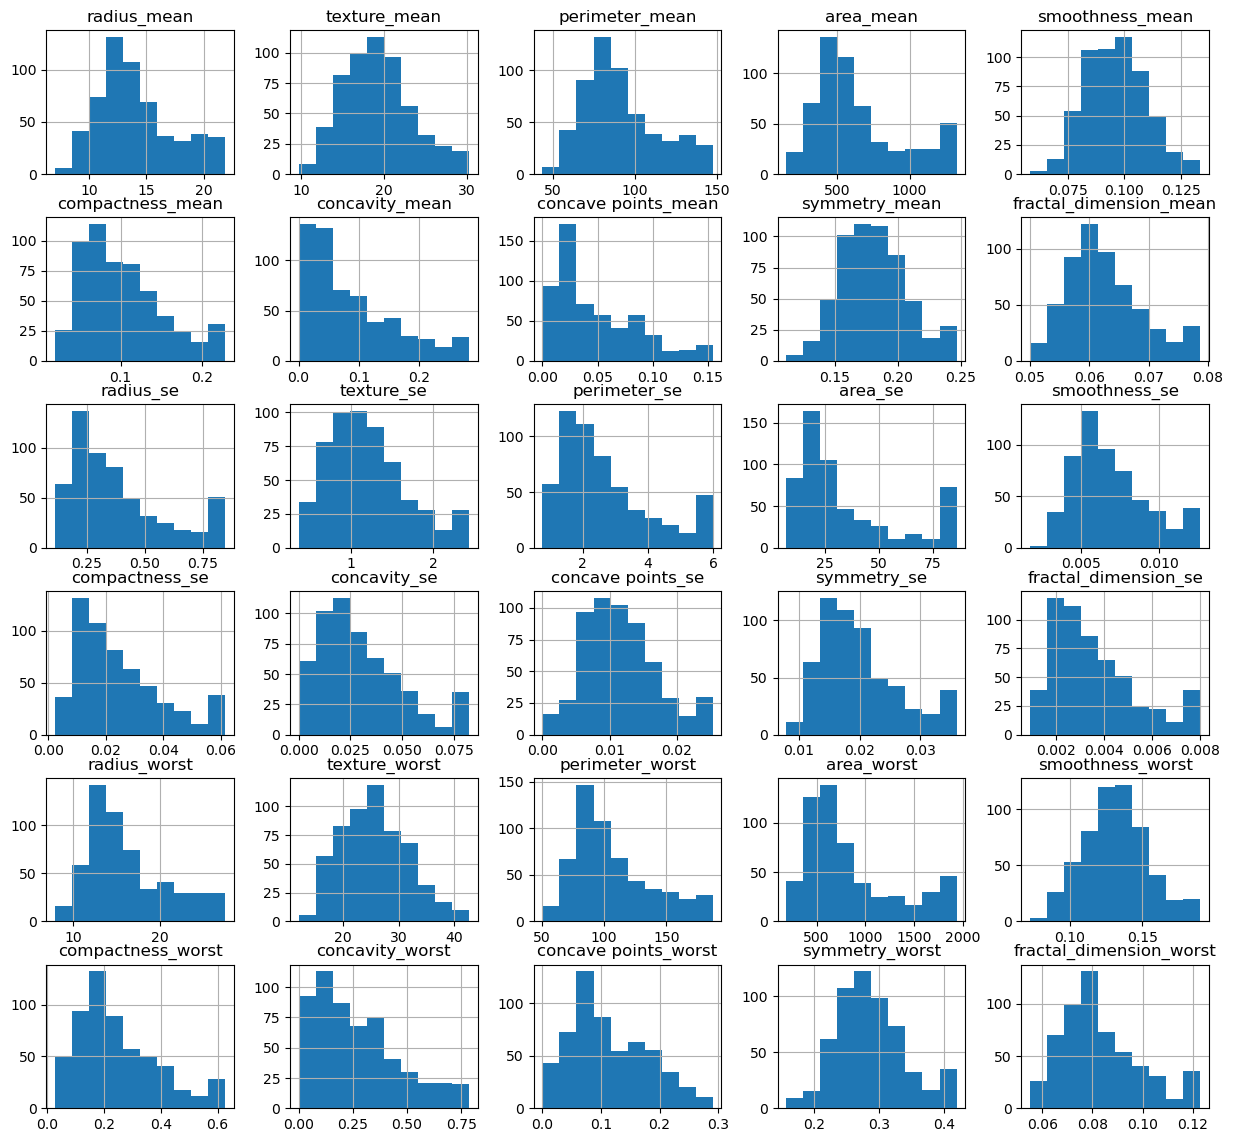

In [24]:
df.hist(figsize=(15,14))
plt.show()

*SCATTER PLOT*

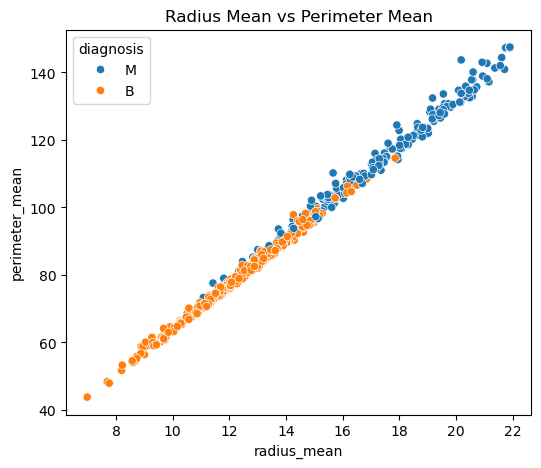

In [25]:
plt.figure(figsize=(6,5))
sns.scatterplot(data=df,
                x='radius_mean',
                y='perimeter_mean',
                hue='diagnosis')
plt.title("Radius Mean vs Perimeter Mean")
plt.show()

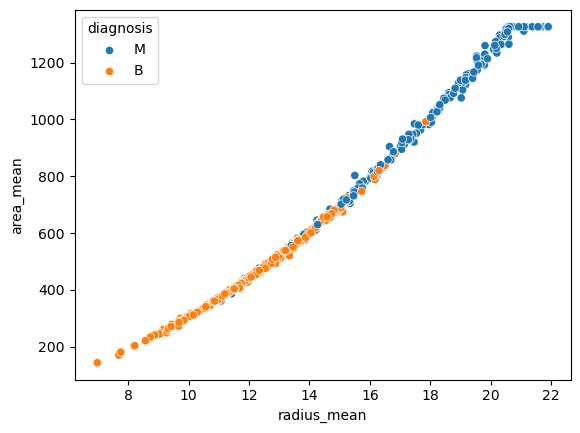

In [26]:
sns.scatterplot(data=df,
                x='radius_mean',
                y='area_mean',
                hue='diagnosis')
plt.show()

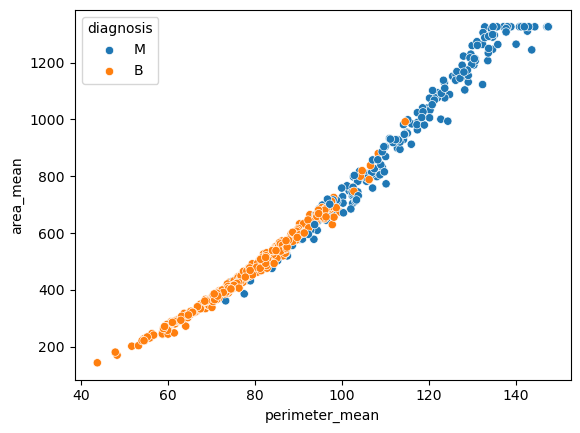

In [27]:
sns.scatterplot(data=df,
                x='perimeter_mean',
                y='area_mean',
                hue='diagnosis')
plt.show()

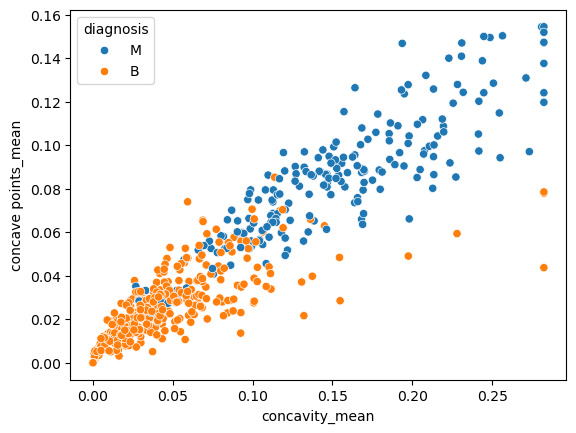

In [28]:
sns.scatterplot(data=df,
                x='concavity_mean',
                y='concave points_mean',
                hue='diagnosis')
plt.show()

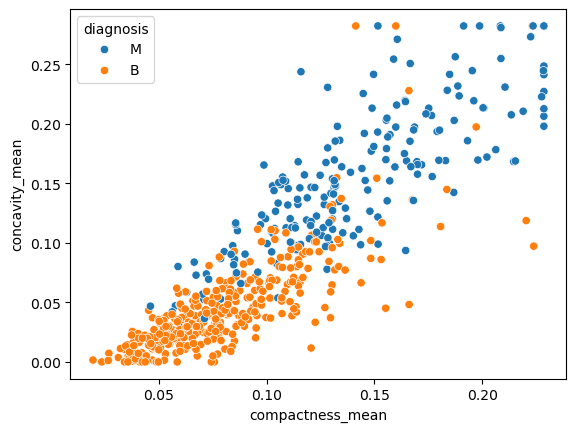

In [29]:
sns.scatterplot(data=df,
                x='compactness_mean',
                y='concavity_mean',
                hue='diagnosis')
plt.show()

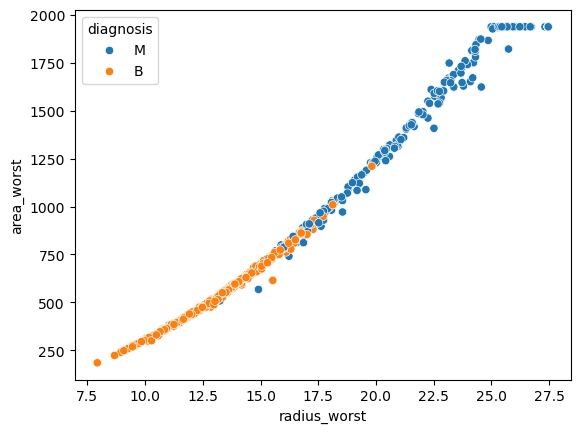

In [30]:
sns.scatterplot(data=df,
                x='radius_worst',
                y='area_worst',
                hue='diagnosis')
plt.show()

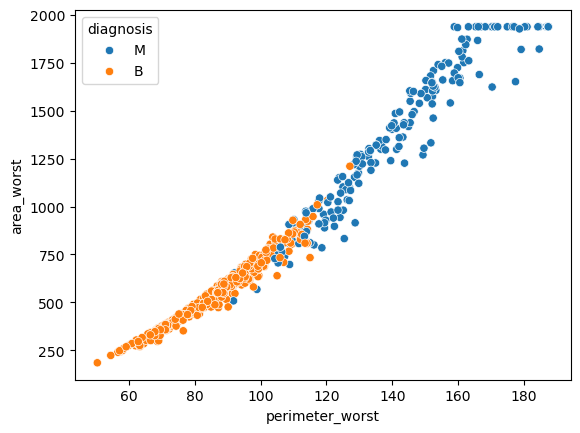

In [31]:
sns.scatterplot(data=df,
                x='perimeter_worst',
                y='area_worst',
                hue='diagnosis')
plt.show()

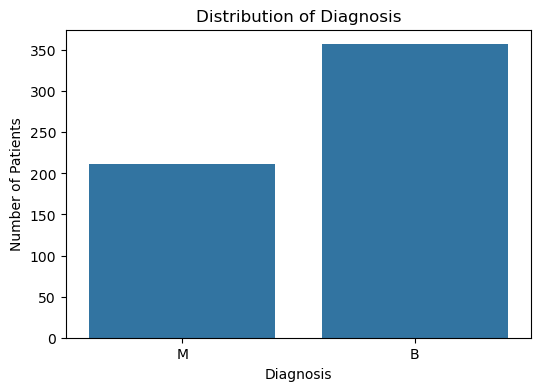

In [32]:
plt.figure(figsize=(6,4))
sns.countplot(x='diagnosis', data=df)
plt.title("Distribution of Diagnosis")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Patients")
plt.show()

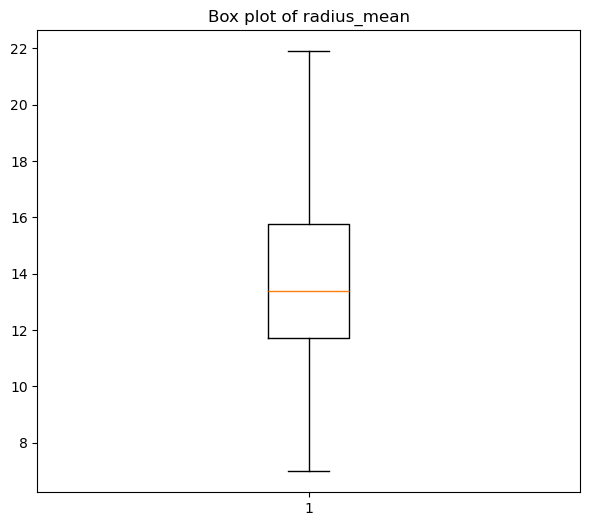

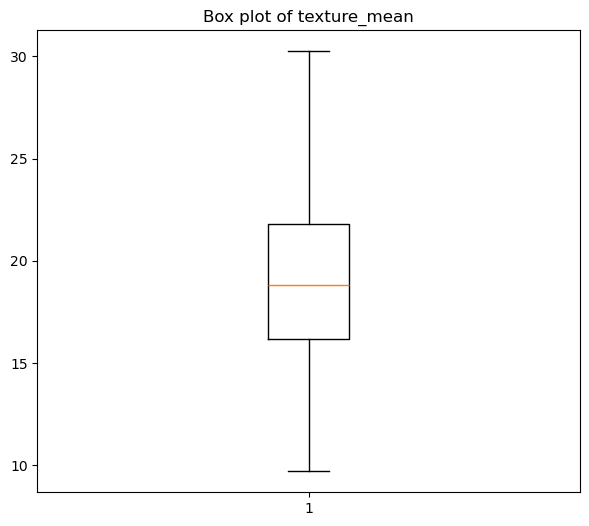

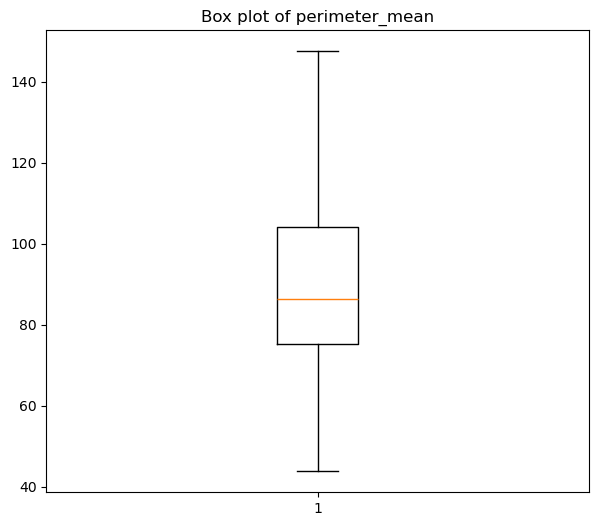

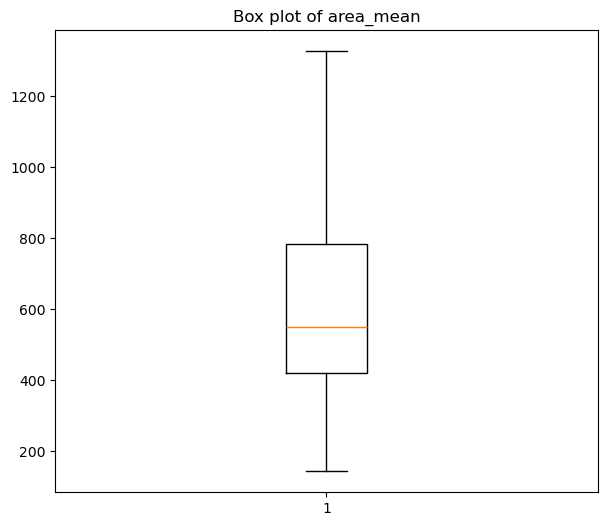

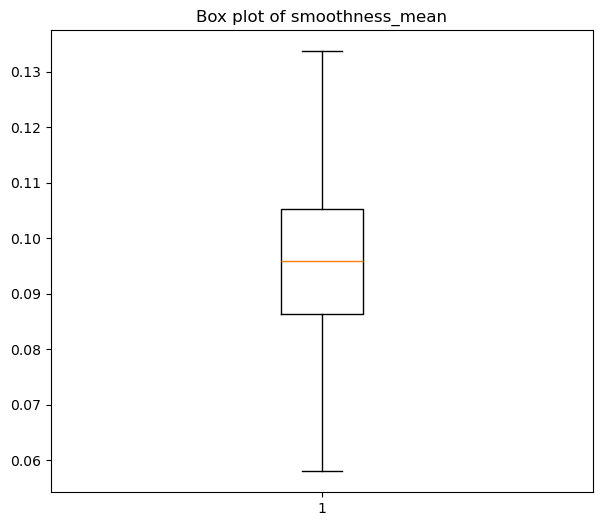

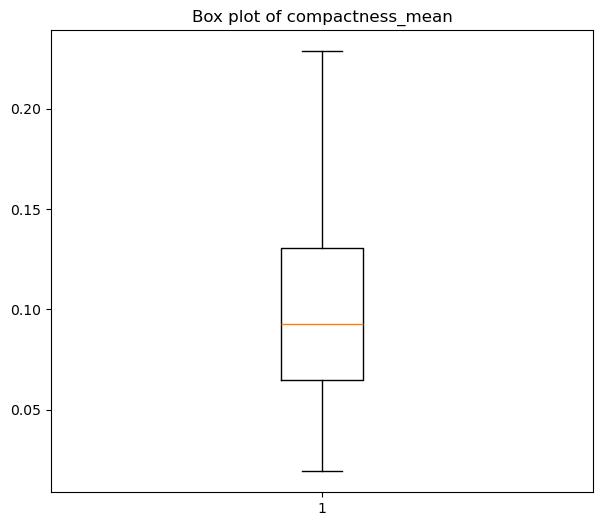

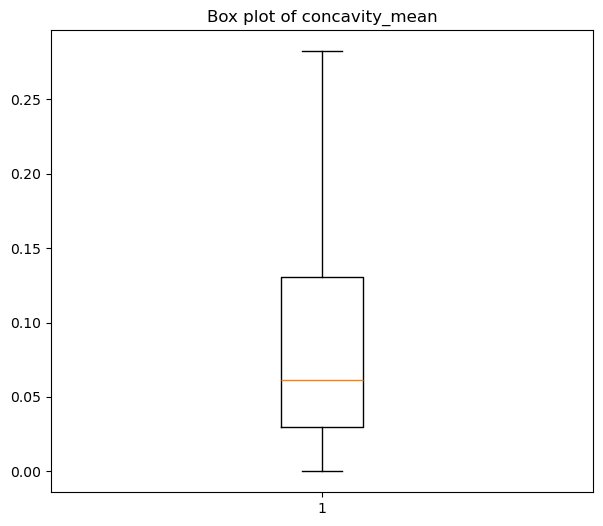

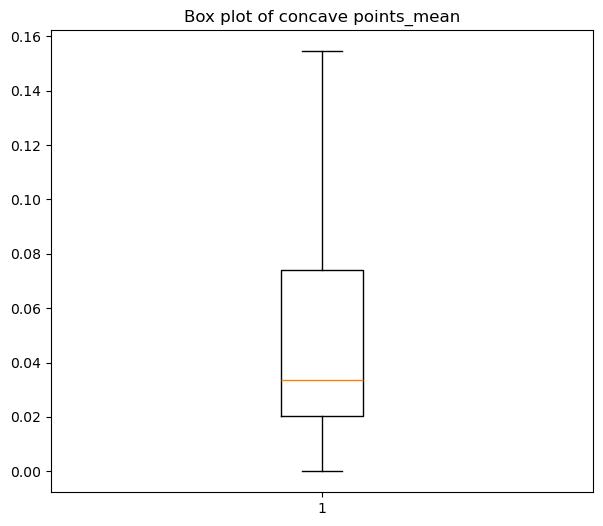

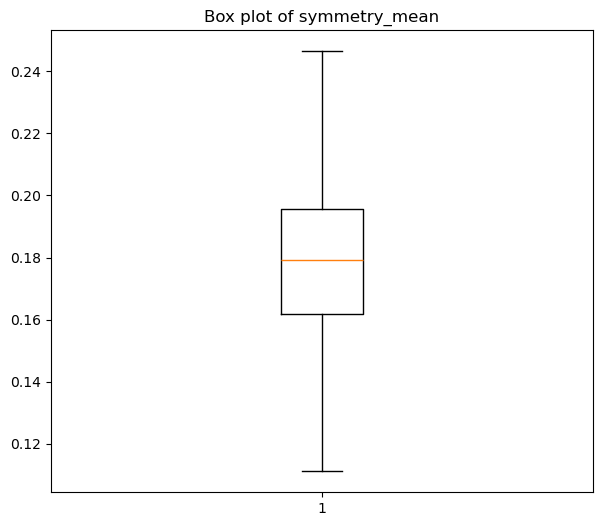

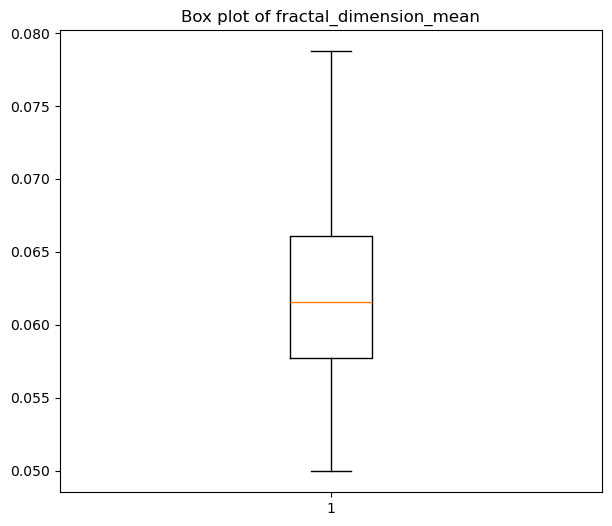

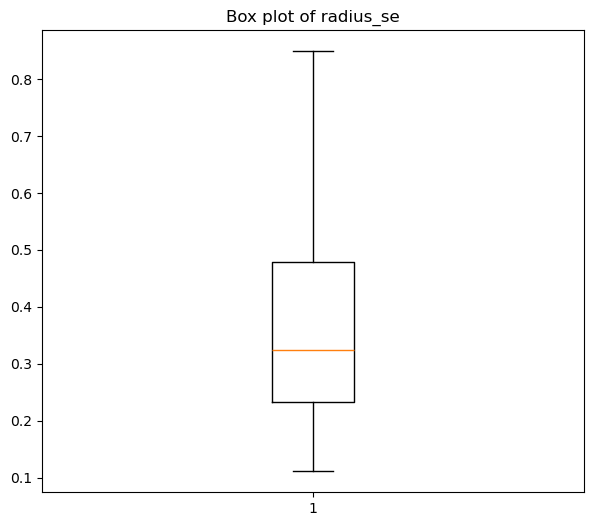

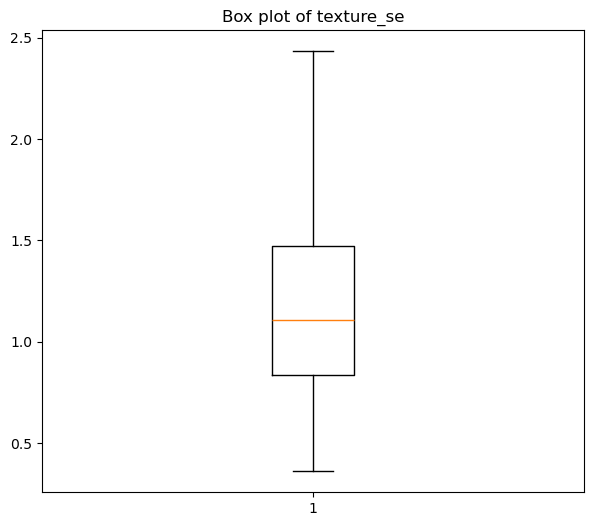

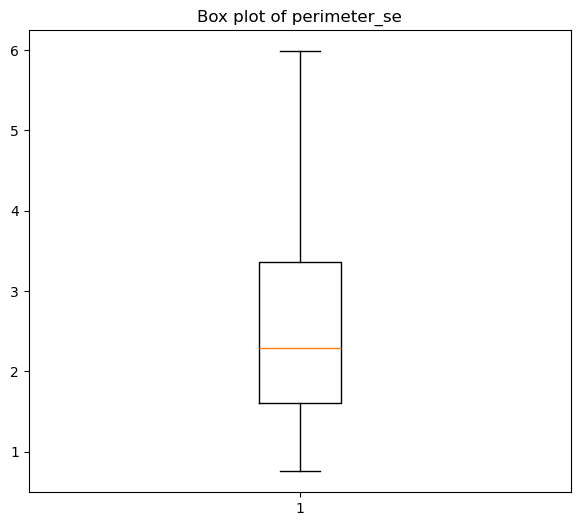

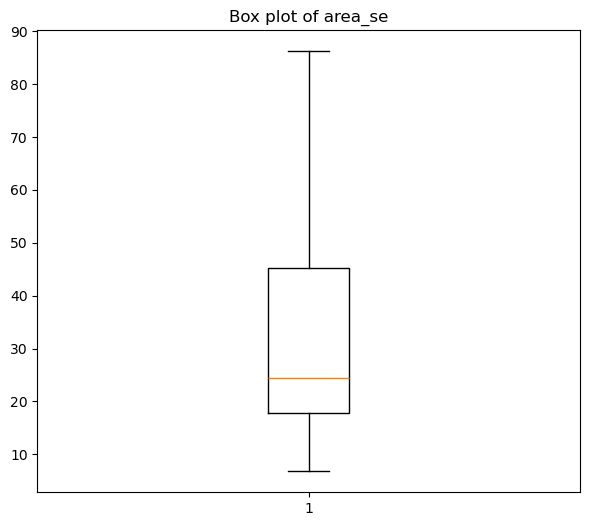

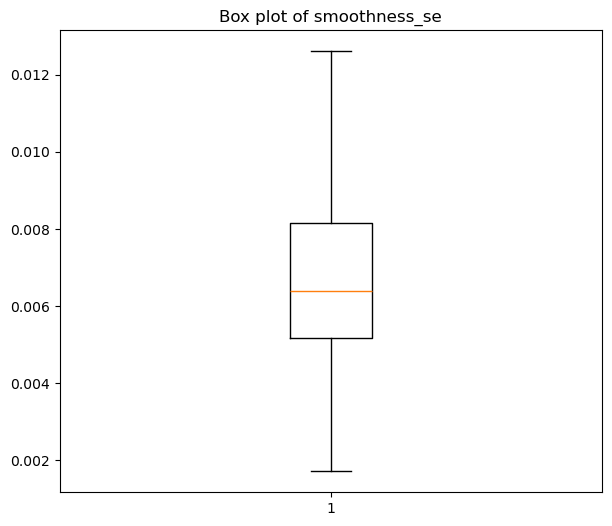

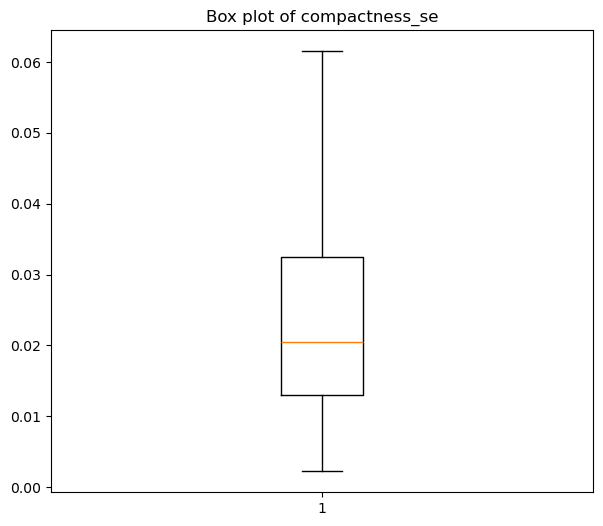

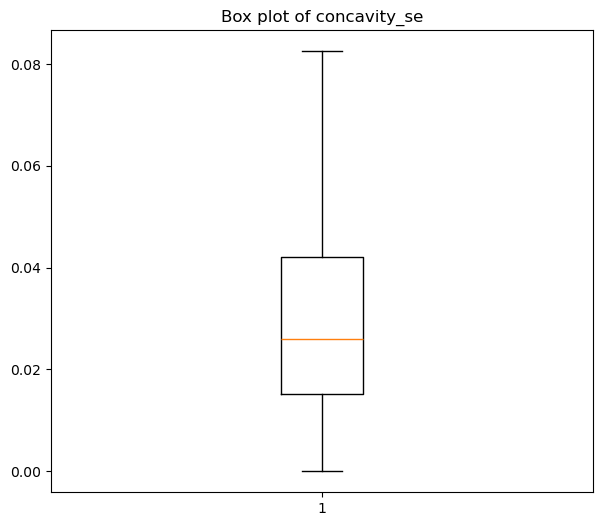

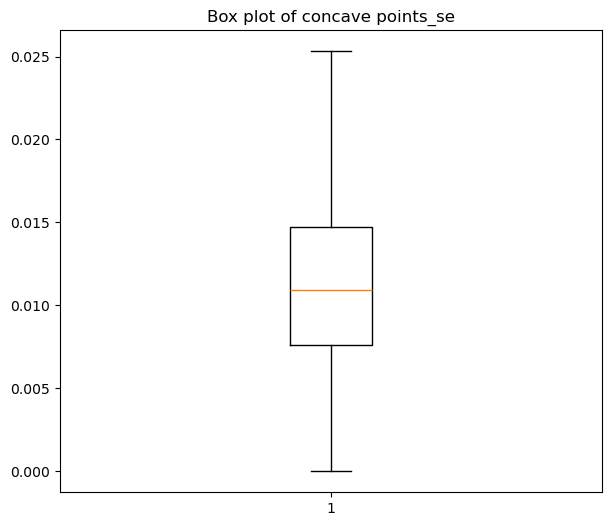

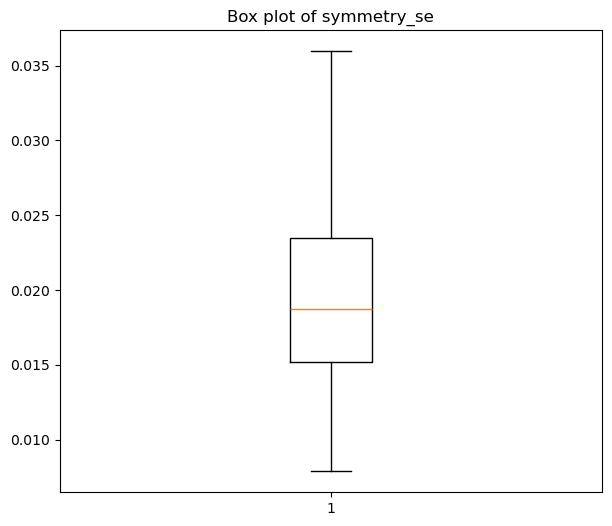

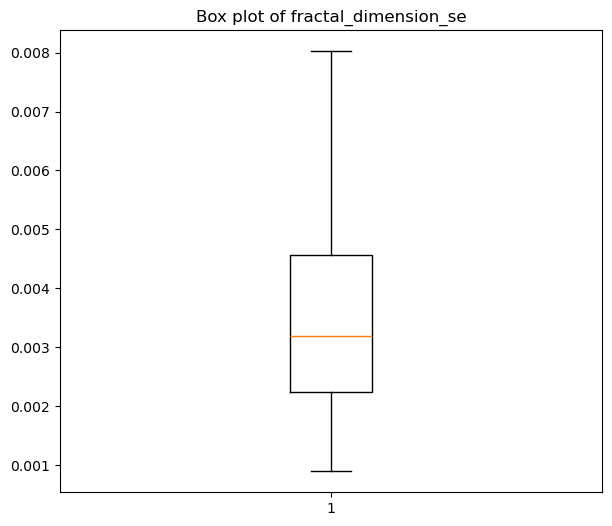

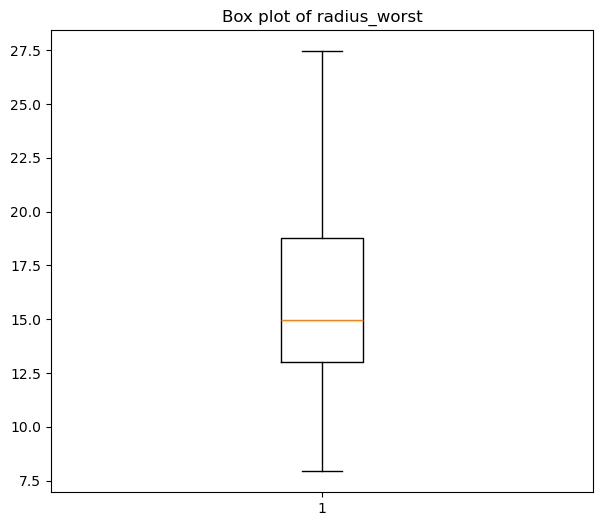

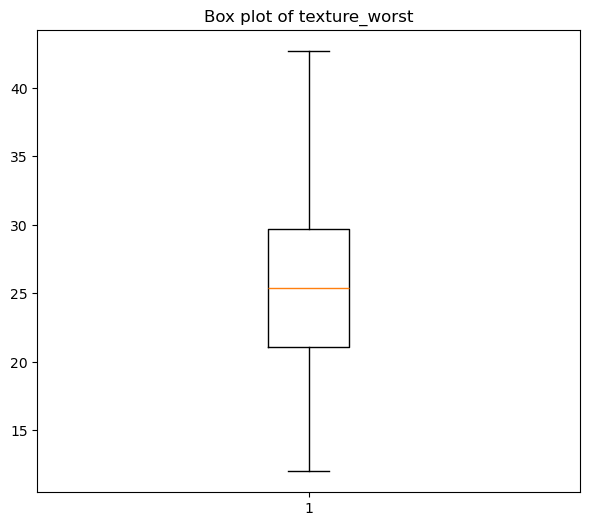

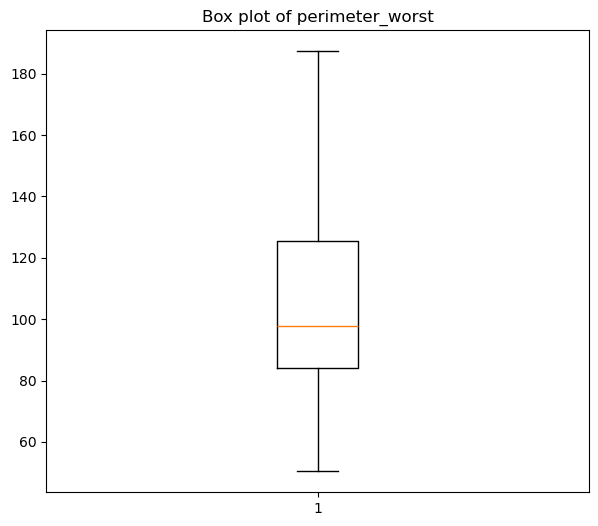

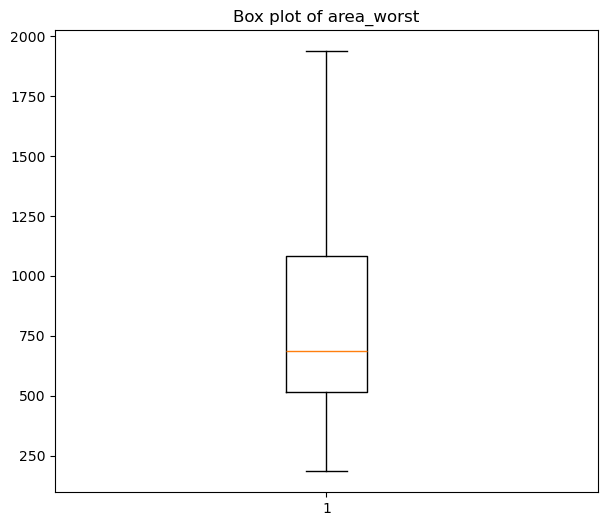

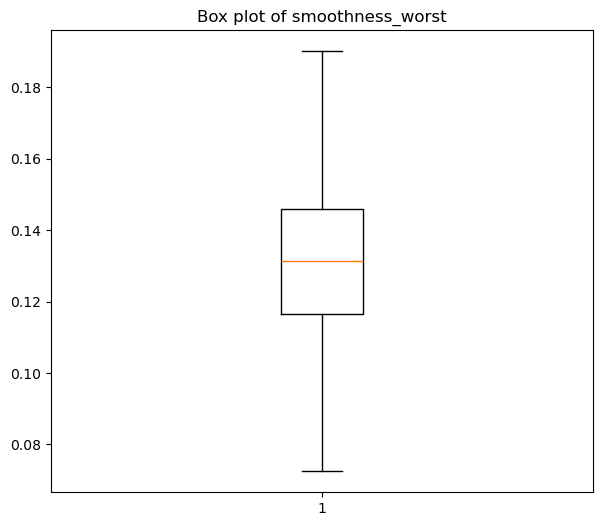

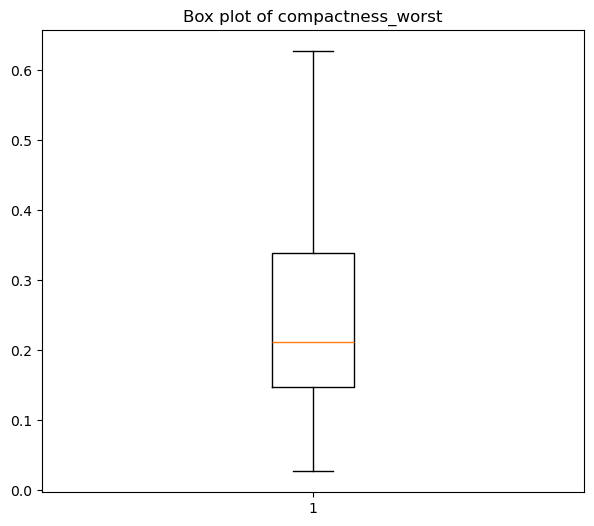

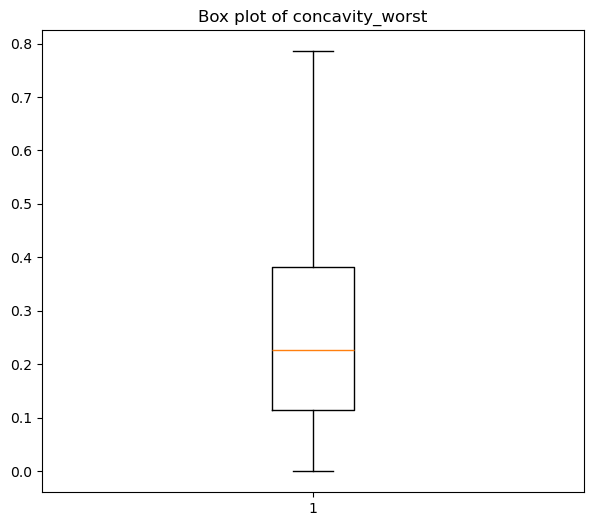

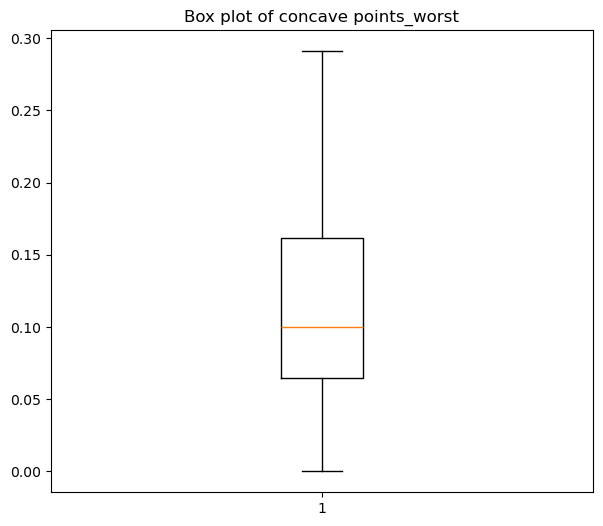

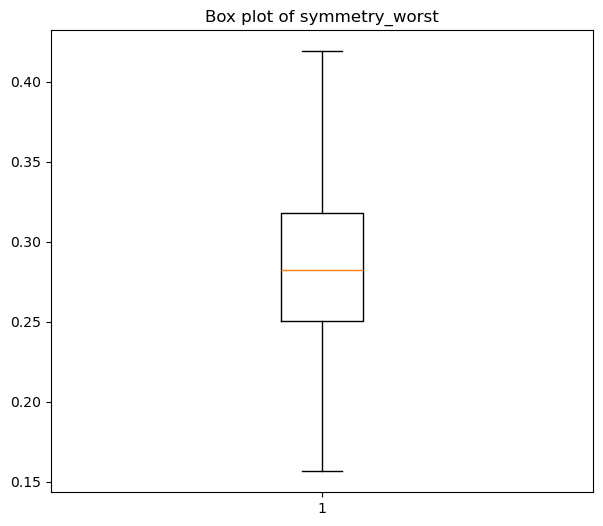

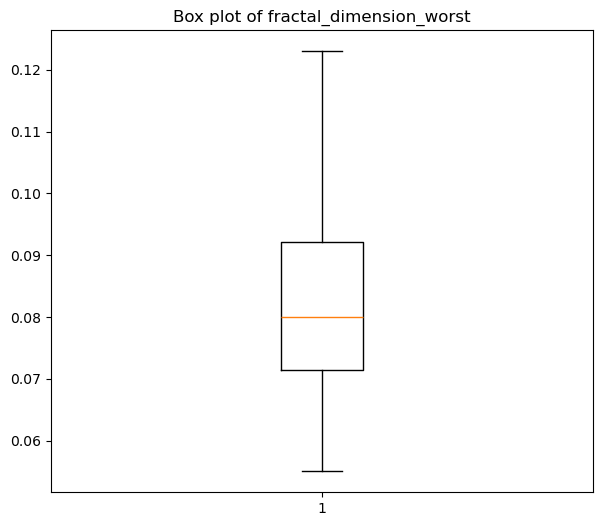

In [33]:
num_cols=df.select_dtypes(include='number').columns
for i in num_cols:
    plt.figure(figsize=(7,6))
    plt.boxplot(df[i])
    plt.title(f"Box plot of {i}")
    plt.show()

### *Feature selection*

*Mapping the Target variable*

In [34]:
df['diagnosis'] = df['diagnosis'].map({'M': 1, 'B': 0})

*CORRELATION*

In [35]:
df.corr()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
diagnosis,1.000000,0.745217,0.419123,0.759006,0.752786,0.366931,0.608494,0.727168,0.788099,0.334536,...,0.793938,0.457663,0.800618,0.794640,0.423390,0.611083,0.683565,0.793566,0.419058,0.328719
radius_mean,0.745217,1.000000,0.332760,0.997692,0.993891,0.167672,0.502741,0.674539,0.811833,0.146763,...,0.973472,0.306225,0.967506,0.962549,0.126332,0.452062,0.559312,0.747817,0.187429,0.028799
texture_mean,0.419123,0.332760,1.000000,0.339588,0.341552,-0.015997,0.241666,0.318654,0.301509,0.079586,...,0.355583,0.911642,0.364127,0.357193,0.077224,0.276731,0.308860,0.296948,0.108611,0.113049
perimeter_mean,0.759006,0.997692,0.339588,1.000000,0.991861,0.204990,0.553698,0.714624,0.841871,0.181325,...,0.974555,0.312741,0.973889,0.963900,0.157912,0.496387,0.597326,0.776769,0.212299,0.075825
area_mean,0.752786,0.993891,0.341552,0.991861,1.000000,0.167400,0.498665,0.680126,0.814133,0.155152,...,0.973784,0.311537,0.967206,0.973460,0.133605,0.441642,0.556230,0.739618,0.185220,0.033012
smoothness_mean,0.366931,0.167672,-0.015997,0.204990,0.167400,1.000000,0.661938,0.526544,0.560961,0.557597,...,0.222464,0.044550,0.246572,0.222205,0.808981,0.482407,0.446253,0.510949,0.403159,0.504675
compactness_mean,0.608494,0.502741,0.241666,0.553698,0.498665,0.661938,1.000000,0.889882,0.832541,0.588842,...,0.542776,0.250386,0.593643,0.537159,0.570701,0.883162,0.835009,0.824531,0.496061,0.710169
concavity_mean,0.727168,0.674539,0.318654,0.714624,0.680126,0.526544,0.889882,1.000000,0.928382,0.489029,...,0.702115,0.316653,0.739514,0.703992,0.462648,0.795115,0.904529,0.881502,0.414279,0.546332
concave points_mean,0.788099,0.811833,0.301509,0.841871,0.814133,0.560961,0.832541,0.928382,1.000000,0.460386,...,0.832188,0.298107,0.855906,0.830127,0.460018,0.701609,0.781051,0.916542,0.384190,0.396626
symmetry_mean,0.334536,0.146763,0.079586,0.181325,0.155152,0.557597,0.588842,0.489029,0.460386,1.000000,...,0.191455,0.099704,0.222826,0.199919,0.431536,0.478419,0.441445,0.430649,0.707566,0.451494


In [36]:
df.shape

(569, 31)

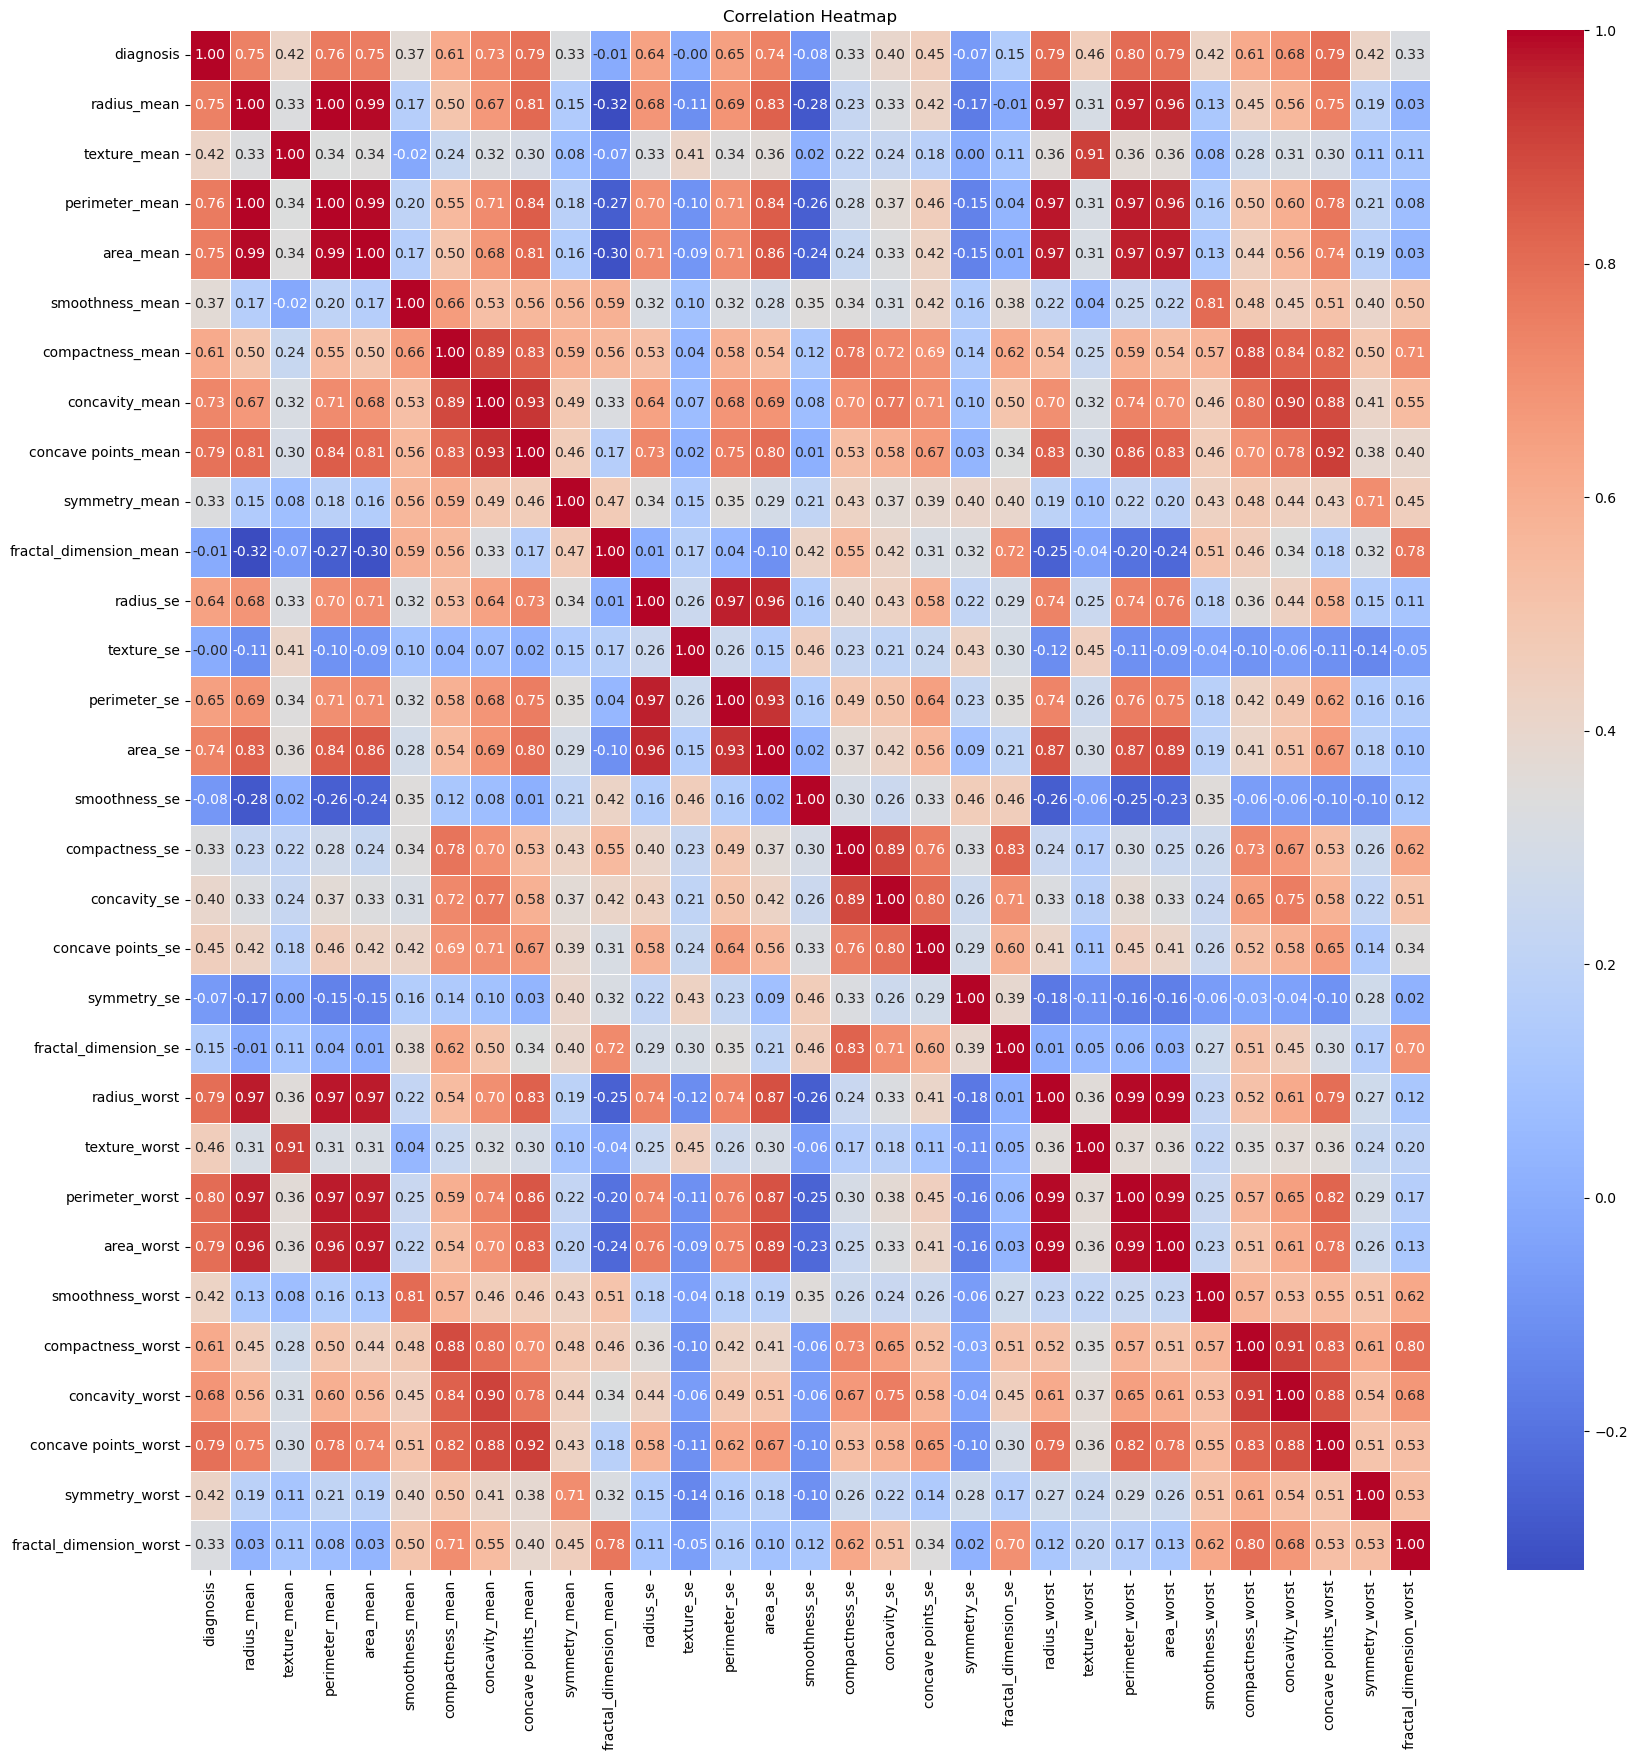

In [37]:
plt.figure(figsize=(20,20))

sns.heatmap(
    df.corr(),
    annot=True,        # Show correlation values
    cmap='coolwarm',   # Color map
    fmt='.2f',         # Display 2 decimal places
    linewidths=0.5
)

plt.title('Correlation Heatmap')
plt.show()

*Sorted correlation with target*

In [38]:
corr_target = df.corr(numeric_only=True)[['diagnosis']].sort_values(
    by='diagnosis',
    key=abs,
    ascending=False
)

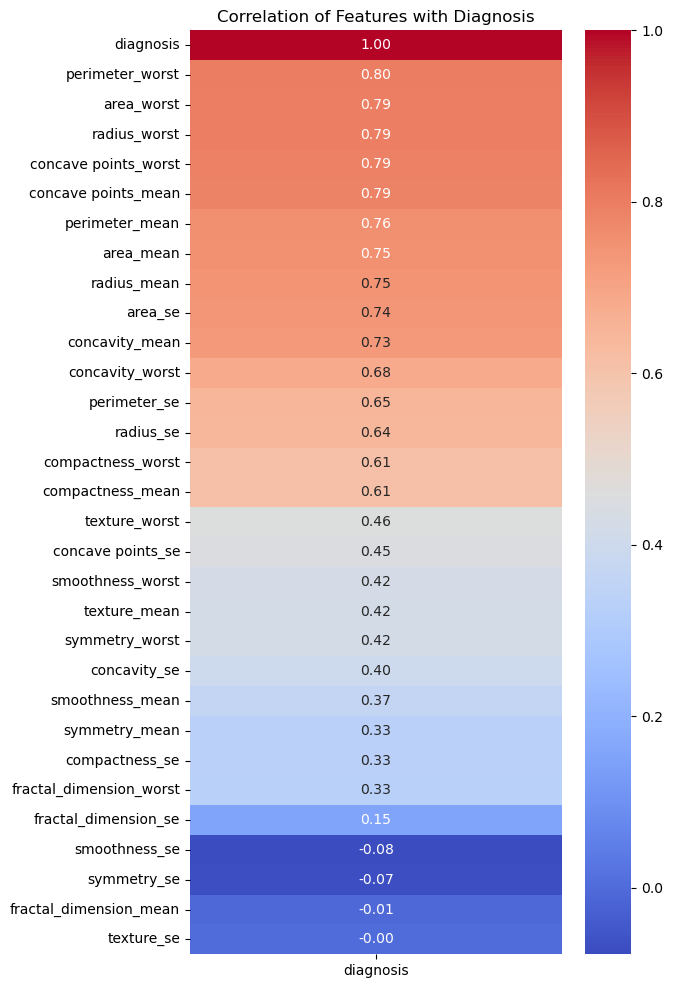

In [39]:
plt.figure(figsize=(6,12))

sns.heatmap(
    corr_target,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation of Features with Diagnosis")
plt.show()

In [40]:
X=df.drop(['diagnosis','texture_worst','concave points_se','smoothness_worst','texture_mean','symmetry_worst','concavity_se','smoothness_mean','symmetry_mean','compactness_se','fractal_dimension_worst','fractal_dimension_se','smoothness_se','symmetry_se','fractal_dimension_mean','texture_se'],axis=1)
y=df['diagnosis']

*Selected Features*

In [41]:
X.columns

Index(['radius_mean', 'perimeter_mean', 'area_mean', 'compactness_mean',
       'concavity_mean', 'concave points_mean', 'radius_se', 'perimeter_se',
       'area_se', 'radius_worst', 'perimeter_worst', 'area_worst',
       'compactness_worst', 'concavity_worst', 'concave points_worst'],
      dtype='object')

#### *DATA TRANSFORMATION*

In [42]:
df['diagnosis'].unique()

array([1, 0])

##### *1.STANDARD SCALER*

In [43]:
SS=StandardScaler()
SS_X=SS.fit_transform(X)
x=pd.DataFrame(SS_X,columns=X.columns)
x

,radius_mean,perimeter_mean,area_mean,compactness_mean,concavity_mean,concave points_mean,radius_se,perimeter_se,area_se,radius_worst,perimeter_worst,area_worst,compactness_worst,concavity_worst,concave points_worst
0,1.176800,1.357375,1.184085,2.541404,2.647422,2.620973,2.280613,2.343091,2.110995,2.006477,2.439568,2.287627,2.641905,2.246192,2.296076
1,1.949929,1.795991,2.249396,-0.498189,-0.000497,0.574944,0.780609,0.498609,1.611678,1.921384,1.631542,2.287627,-0.443388,-0.137634,1.087084
2,1.686226,1.670052,1.846217,1.148680,1.496076,2.110330,1.774057,1.345409,2.110995,1.611558,1.434234,1.807751,1.223448,0.920718,1.955000
3,-0.791983,-0.606410,-0.831485,2.541404,2.091997,1.506601,0.545151,0.532139,-0.318438,-0.277945,-0.245395,-0.593838,2.641905,2.119474,2.175786
4,1.866023,1.891531,2.154338,0.599453,1.504202,1.482665,1.831079,1.953934,2.110995,1.386825,1.424838,1.525780,-0.314469,0.665254,0.729259
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,2.246595,2.191180,2.250380,0.256947,2.125856,2.402886,2.280613,2.343091,2.110995,2.021750,1.860170,2.287627,-0.270329,0.719489,1.629151
565,1.818077,1.722165,2.036334,0.003614,0.772845,1.312717,1.871878,1.786287,2.110995,1.637740,1.512531,1.854045,-0.404152,0.267358,0.733827
566,0.760269,0.727678,0.715676,-0.018680,0.075483,0.118824,0.352458,0.517871,0.559899,0.610078,0.626208,0.576760,0.417005,0.362650,0.414069
567,1.958919,2.108668,2.049446,2.541404,2.647422,2.751293,1.677711,2.192208,2.110995,2.085025,2.439568,2.043428,2.641905,2.619251,2.289985


In [44]:
x.head()

,radius_mean,perimeter_mean,area_mean,compactness_mean,concavity_mean,concave points_mean,radius_se,perimeter_se,area_se,radius_worst,perimeter_worst,area_worst,compactness_worst,concavity_worst,concave points_worst
0,1.176800,1.357375,1.184085,2.541404,2.647422,2.620973,2.280613,2.343091,2.110995,2.006477,2.439568,2.287627,2.641905,2.246192,2.296076
1,1.949929,1.795991,2.249396,-0.498189,-0.000497,0.574944,0.780609,0.498609,1.611678,1.921384,1.631542,2.287627,-0.443388,-0.137634,1.087084
2,1.686226,1.670052,1.846217,1.148680,1.496076,2.110330,1.774057,1.345409,2.110995,1.611558,1.434234,1.807751,1.223448,0.920718,1.955000
3,-0.791983,-0.606410,-0.831485,2.541404,2.091997,1.506601,0.545151,0.532139,-0.318438,-0.277945,-0.245395,-0.593838,2.641905,2.119474,2.175786
4,1.866023,1.891531,2.154338,0.599453,1.504202,1.482665,1.831079,1.953934,2.110995,1.386825,1.424838,1.525780,-0.314469,0.665254,0.729259


##### *DATA PARTITION*

In [45]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.3,random_state=42)

#### *Model Selection*

In [46]:
gb_model = GradientBoostingClassifier(random_state=42)

##### *MODEL FIT*

In [47]:
gb_model.fit(x_train, y_train)

,loss,'log_loss'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


##### *PREDICTING THE VALUES*

In [48]:
y_train_pred = gb_model.predict(x_train)
y_test_pred = gb_model.predict(x_test)

##### *MODEL EVALUATION*

In [52]:
#MODEL EVALUATION 
print("Training Accuracy :", accuracy_score(y_train, y_train_pred))
print("Testing Accuracy  :", accuracy_score(y_test, y_test_pred))
print()

print("train Log Loss :", log_loss(y_train, y_train_pred))
print("test Log Loss  :", log_loss(y_test, y_test_pred))
print()

print("Precision :", precision_score(y_test, y_test_pred))
print("Recall    :", recall_score(y_test, y_test_pred))
print("F1 Score  :", f1_score(y_test, y_test_pred))
print()

print("Confusion Matrix")
print(confusion_matrix(y_test, y_test_pred))
print()

print("Classification Report")
print(classification_report(y_test, y_test_pred))

Training Accuracy : 1.0
Testing Accuracy  : 0.9415204678362573

train Log Loss : 2.2204460492503136e-16
test Log Loss  : 2.10781598766767

Precision : 0.9076923076923077
Recall    : 0.9365079365079365
F1 Score  : 0.921875

Confusion Matrix
[[102   6]
 [  4  59]]

Classification Report
              precision    recall  f1-score   support

           0       0.96      0.94      0.95       108
           1       0.91      0.94      0.92        63

    accuracy                           0.94       171
   macro avg       0.93      0.94      0.94       171
weighted avg       0.94      0.94      0.94       171



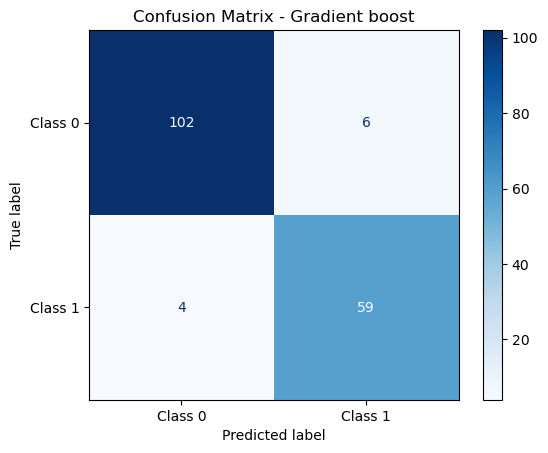

In [53]:
#confusion matrix
cm_gb = confusion_matrix(y_test, y_test_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_gb,
    display_labels=['Class 0', 'Class 1']
)

disp.plot(cmap='Blues')
plt.title("Confusion Matrix - Gradient boost")
plt.show()

##### *GRID SEARCH*

In [54]:
# Parameter Grid
param_grid = {
    'n_estimators': [50, 100, 150],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'max_depth': [2, 3, 4, 5],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'subsample': [0.8, 1.0]
}

# Grid Search
grid = GridSearchCV(
    estimator=gb_model,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid.fit(x_train, y_train)

,estimator,GradientBoost...ndom_state=42)
,param_grid,"{'learning_rate': [0.01, 0.05, ...], 'max_depth': [2, 3, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], ...}"
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,loss,'log_loss'


In [55]:
print("Best Parameters :", grid.best_params_)
print("Best Cross Validation Score :", grid.best_score_)

Best Parameters : {'learning_rate': 0.1, 'max_depth': 4, 'min_samples_leaf': 4, 'min_samples_split': 2, 'n_estimators': 150, 'subsample': 0.8}
Best Cross Validation Score : 0.9472468354430379


In [56]:
final_model = grid.best_estimator_
print(final_model)

GradientBoostingClassifier(max_depth=4, min_samples_leaf=4, n_estimators=150,
                           random_state=42, subsample=0.8)


In [57]:
y_train_pred = final_model.predict(x_train)
y_test_pred = final_model.predict(x_test)

In [58]:
print("Training Accuracy :", accuracy_score(y_train, y_train_pred))
print("Testing Accuracy  :", accuracy_score(y_test, y_test_pred))
print()

print("training Log Loss :", log_loss(y_train, y_train_pred))
print("Testing Log Loss  :", log_loss(y_test, y_test_pred))
print()

print("Precision :", precision_score(y_test, y_test_pred))
print("Recall    :", recall_score(y_test, y_test_pred))
print("F1 Score  :", f1_score(y_test, y_test_pred))
print()

print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_test_pred))
print()

print("\nClassification Report")
print(classification_report(y_test, y_test_pred))

Training Accuracy : 1.0
Testing Accuracy  : 0.9473684210526315

training Log Loss : 2.2204460492503136e-16
Testing Log Loss  : 1.8970343889009027

Precision : 0.9354838709677419
Recall    : 0.9206349206349206
F1 Score  : 0.928


Confusion Matrix
[[104   4]
 [  5  58]]


Classification Report
              precision    recall  f1-score   support

           0       0.95      0.96      0.96       108
           1       0.94      0.92      0.93        63

    accuracy                           0.95       171
   macro avg       0.94      0.94      0.94       171
weighted avg       0.95      0.95      0.95       171



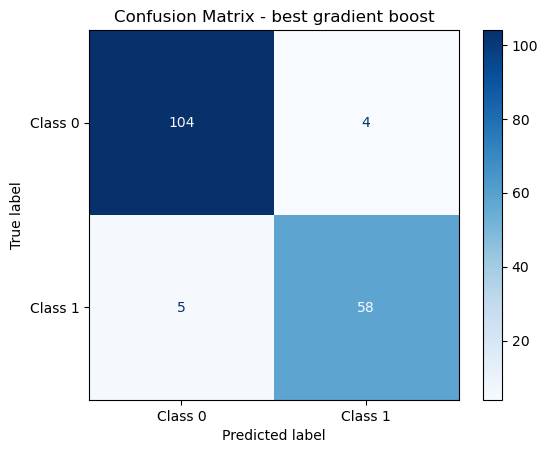

In [59]:
#confusion matrix visual representation
cm_best = confusion_matrix(y_test, y_test_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_best,
    display_labels=['Class 0', 'Class 1']   # Replace if needed
)

disp.plot(cmap='Blues')
plt.title("Confusion Matrix - best gradient boost")
plt.show()

#### *TRAIN THE FINAL MODEL*

In [60]:
# Final Optimized Model
final_model = grid.best_estimator_

print(final_model)

GradientBoostingClassifier(max_depth=4, min_samples_leaf=4, n_estimators=150,
                           random_state=42, subsample=0.8)


In [61]:
y_train_pred_final = final_model.predict(x_train)
y_test_pred_final = final_model.predict(x_test)

In [62]:
print("Training Accuracy :", accuracy_score(y_train, y_train_pred_final))
print("Testing Accuracy  :", accuracy_score(y_test, y_test_pred_final))

print("\nPrecision :", precision_score(y_test, y_test_pred_final))
print("Recall    :", recall_score(y_test, y_test_pred_final))
print("F1 Score  :", f1_score(y_test, y_test_pred_final))

print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_test_pred_final))

print("\nClassification Report")
print(classification_report(y_test, y_test_pred_final))

Training Accuracy : 1.0
Testing Accuracy  : 0.9473684210526315

Precision : 0.9354838709677419
Recall    : 0.9206349206349206
F1 Score  : 0.928

Confusion Matrix
[[104   4]
 [  5  58]]

Classification Report
              precision    recall  f1-score   support

           0       0.95      0.96      0.96       108
           1       0.94      0.92      0.93        63

    accuracy                           0.95       171
   macro avg       0.94      0.94      0.94       171
weighted avg       0.95      0.95      0.95       171



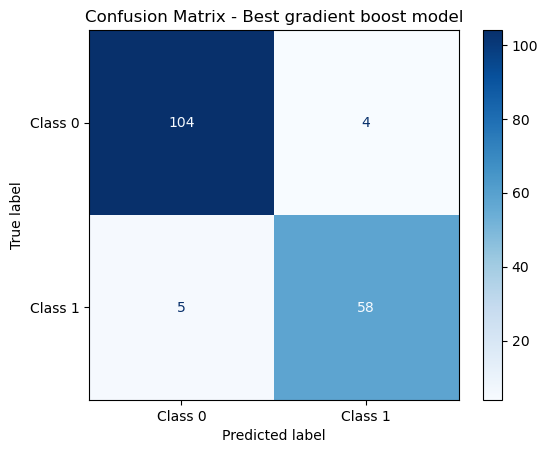

In [63]:
cm_final = confusion_matrix(y_test, y_test_pred_final)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_final,
    display_labels=['Class 0', 'Class 1']   # Replace if needed
)

disp.plot(cmap='Blues')
plt.title("Confusion Matrix - Best gradient boost model")
plt.show()

##### *CROSS VALIDATION*

* This checks whether the model performs consistently on different subsets of the data.

In [64]:
cv_scores = cross_val_score(
    final_model,
    X,
    y,
    cv=10,
    scoring='accuracy'
)

print("Cross Validation Scores:")
print(cv_scores)

print("\nMean Cross Validation Accuracy:", cv_scores.mean())

print("Standard Deviation:", cv_scores.std())

Cross Validation Scores:
[0.9122807  0.89473684 0.89473684 0.94736842 0.96491228 0.96491228
 0.92982456 0.98245614 0.94736842 0.98214286]

Mean Cross Validation Accuracy: 0.9420739348370928
Standard Deviation: 0.031392306211527894


CONFUSION MATRIX

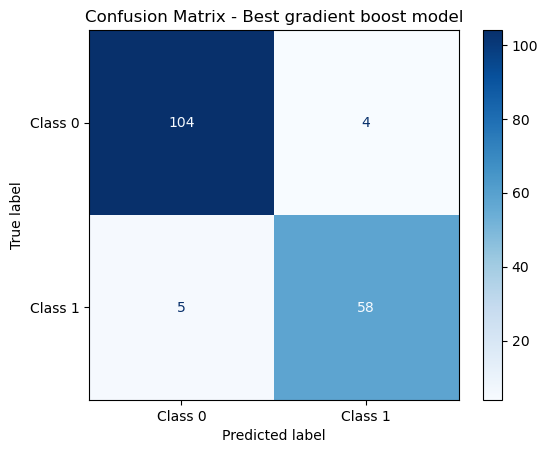

In [65]:
cm_final = confusion_matrix(y_test, y_test_pred_final)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_final,
    display_labels=['Class 0', 'Class 1']   # Replace if needed
)

disp.plot(cmap='Blues')
plt.title("Confusion Matrix - Best gradient boost model")
plt.show()

##### *ROC CURVE*

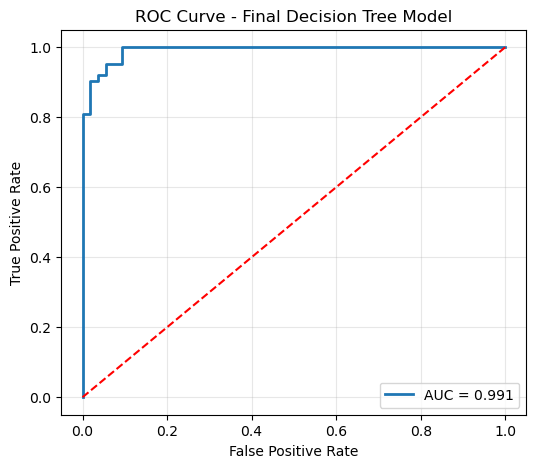

In [66]:
# Probability predictions
y_prob = final_model.predict_proba(x_test)[:, 1]

# ROC values
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# AUC Score
auc_score = roc_auc_score(y_test, y_prob)

# Plot ROC Curve
plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, linewidth=2, label=f"AUC = {auc_score:.3f}")
plt.plot([0,1], [0,1], 'r--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Final Decision Tree Model")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.show()

##### *Predicting the new values*

In [68]:
x.columns

Index(['radius_mean', 'perimeter_mean', 'area_mean', 'compactness_mean',
       'concavity_mean', 'concave points_mean', 'radius_se', 'perimeter_se',
       'area_se', 'radius_worst', 'perimeter_worst', 'area_worst',
       'compactness_worst', 'concavity_worst', 'concave points_worst'],
      dtype='object')

In [69]:
new_data = pd.DataFrame({
    'radius_mean': [14.5],
    'perimeter_mean': [95.2],
    'area_mean': [650.4],
    'compactness_mean': [0.12],
    'concavity_mean': [0.15],
    'concave points_mean': [0.08],
    'radius_se': [0.45],
    'perimeter_se': [2.8],
    'area_se': [40.5],
    'radius_worst': [16.8],
    'perimeter_worst': [110.4],
    'area_worst': [850.2],
    'compactness_worst': [0.25],
    'concavity_worst': [0.32],
    'concave points_worst': [0.18]
})

In [70]:
new_data_scaled = SS.transform(new_data)

In [71]:
prediction = final_model.predict(new_data_scaled)

print(prediction)

[1]


In [72]:
if prediction[0] == 0:
    print("Prediction: Benign Tumor")
else:
    print("Prediction: Malignant Tumor")

Prediction: Malignant Tumor


* A benign tumor is non-cancerous.
* A malignant tumor is cancerous.

*Save the Trained model*

In [73]:
import pickle

with open("model.pkl", "wb") as file:
    pickle.dump(final_model, file)

*save the Standard Scaler*

In [74]:
with open("scaler.pkl", "wb") as file:
    pickle.dump(SS, file)

*Save the Features names*

In [75]:
feature_names = x.columns.tolist()

with open("features.pkl", "wb") as file:
    pickle.dump(feature_names, file)